# Tracking and growth-history evaluation

**Paper:** *YOLO26-L-seg for Oyster Mushroom Cluster Segmentation and Growth Monitoring*

This notebook evaluates the temporal association and growth-history stage of the study. It consumes the cached YOLO26-L-seg instance predictions and annotated source identities exported by `full-inference.ipynb`. It does not rerun YOLO26-L-seg or Mask R-CNN inference, repeat segmentation evaluation, or optimize tracker parameters.

The tracker configuration was frozen using validation data before this evaluation. The test split contains 528 sampled frames from sequences 1 and 3. Source images were acquired at 15-minute intervals; the evaluated frames are separated by eight source-frame indices, corresponding to a nominal two-hour interval. Ground-truth identities are sequence-scoped and are represented by `(SEQUENCE_ID, GT_TRACK_ID)`.

The analysis evaluates frame-level detection matching, identity consistency, whole-track identity purity, strict source-consistent history coverage, geometric measurement error, and temporal area-change agreement. It also exports publication figures and machine-readable evidence tables.

All geometric measurements in this notebook are in image-space pixels or pixels squared. No physical-scale calibration is applied; these results do not establish dimensions in centimetres or biological growth rates.


In [1]:
from pathlib import Path
from collections import defaultdict, Counter, OrderedDict
import os, re, io, json, gzip, zipfile, hashlib, math, time, platform, warnings, shutil
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from IPython.display import display
from tqdm.auto import tqdm

try:
    from numba import njit
    NUMBA_AVAILABLE = True
except Exception:
    NUMBA_AVAILABLE = False
    def njit(*args, **kwargs):
        def wrap(fn): return fn
        return wrap

# Set an explicit path only if automatic discovery is ambiguous.
EVIDENCE_BUNDLE_PATH = os.environ.get('FUNGICIRNO_EVIDENCE_BUNDLE') or None
KAGGLE_INPUT = Path('/kaggle/input')
KAGGLE_WORKING = Path('/kaggle/working')
SEARCH_ROOTS = []
for root in [KAGGLE_INPUT, KAGGLE_WORKING, Path('/mnt/data'), Path.cwd()]:
    try:
        resolved = root.resolve()
        if root.exists() and resolved != Path('/').resolve() and resolved not in {p.resolve() for p in SEARCH_ROOTS}:
            SEARCH_ROOTS.append(root)
    except (OSError, RuntimeError):
        pass

if KAGGLE_WORKING.exists():
    OUTPUT_DIR = KAGGLE_WORKING / 'FungiCirno_Tracking_Growth_Evaluation_Final'
else:
    fallback = Path.cwd()
    if fallback.resolve() == Path('/').resolve():
        fallback = Path('/mnt/data') if Path('/mnt/data').exists() else Path.home()
    OUTPUT_DIR = fallback / 'FungiCirno_Tracking_Growth_Evaluation_Final'
FIGURE_DIR = OUTPUT_DIR / 'figures'
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PAPER_TITLE = 'YOLO26-L-seg for Oyster Mushroom Cluster Segmentation and Growth Monitoring'
CURRENT_FULL_INFERENCE_NOTEBOOK = 'full-inference.ipynb'
FINAL_EVALUATION_NOTEBOOK = 'FungiCirno_Tracking_and_Growth_History_Evaluation_Final.ipynb'
MASK_MATCH_IOU = 0.50
STRICT_PURITY_THRESHOLD = 0.90
SOURCE_CADENCE_MINUTES = 15.0
TEST_SAMPLE_STRIDE = 8
NOMINAL_SAMPLE_INTERVAL_HOURS = SOURCE_CADENCE_MINUTES * TEST_SAMPLE_STRIDE / 60.0
print('Numba available:', NUMBA_AVAILABLE)
print('Evidence search roots:', [str(p) for p in SEARCH_ROOTS])
print('Output directory:', OUTPUT_DIR)

Numba available: True
Evidence search roots: ['/kaggle/input', '/kaggle/working']
Output directory: /kaggle/working/FungiCirno_Tracking_Growth_Evaluation_Final


In [2]:
YOLO_CACHE_MEMBER = 'fresh_prediction_records/fresh_yolo26_frame_predictions.jsonl'
MANIFEST_MEMBER = 'run_manifest.json'
EXPECTED_HIGH = 0.8710562586784363

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def _prediction_cache_suffixes():
    """Canonical relative names; discovery accepts plain .jsonl and .jsonl.gz."""
    return (
        'fresh_prediction_records/fresh_yolo26_frame_predictions.jsonl',
        'fresh_prediction_records/fresh_maskrcnn_frame_predictions.jsonl',
    )


def _has_exactly_one_cache(names, suffix):
    suffix = suffix.lower().removesuffix('.gz')
    hits = [name for name in names
            if name.replace('\\', '/').lower().removesuffix('.gz').endswith(suffix)]
    return len(hits) == 1


def zip_has_required_members(path):
    """Recognize evidence ZIPs containing manifest and both prediction caches.

    Prediction caches may be stored as plain JSONL or gzip-compressed JSONL.
    """
    try:
        with zipfile.ZipFile(path) as zf:
            names = [n.replace('\\', '/').lower() for n in zf.namelist()]
            return (
                sum(n.endswith('run_manifest.json') for n in names) == 1
                and all(_has_exactly_one_cache(names, suffix)
                        for suffix in _prediction_cache_suffixes())
            )
    except (OSError, zipfile.BadZipFile, RuntimeError):
        return False


def _iter_files_recursive(root):
    """Yield files below root, skipping inaccessible paths without aborting discovery."""
    try:
        for path in root.rglob('*'):
            try:
                if path.is_file():
                    yield path
            except (OSError, PermissionError):
                continue
    except (OSError, PermissionError):
        return


def _directory_has_required_members(root, files=None):
    """Validate an extracted evidence bundle with either JSONL encoding."""
    if files is None:
        files = list(_iter_files_recursive(root))
    names = [p.relative_to(root).as_posix().lower()
             for p in files if p.is_relative_to(root)]
    return (
        sum(n.endswith('run_manifest.json') for n in names) == 1
        and all(_has_exactly_one_cache(names, suffix)
                for suffix in _prediction_cache_suffixes())
    )


def discover_evidence_bundle(explicit=None):
    """Find a FungiCirno ZIP or extracted folder recursively.

    The Kaggle test-tracker dataset is already extracted under
    /kaggle/input/datasets/hnamedu/test-tracker and stores prediction caches as
    plain .jsonl files. Other releases may package gzip-compressed .jsonl.gz.
    """
    if explicit:
        p = Path(explicit).expanduser()
        if not p.exists():
            raise FileNotFoundError(f'EVIDENCE_BUNDLE_PATH does not exist: {p}')
        if p.is_file() and p.suffix.lower() == '.zip' and zip_has_required_members(p):
            return p.resolve()
        if p.is_dir() and _directory_has_required_members(p):
            return p.resolve()
        raise RuntimeError(
            f'Input does not contain exactly one run_manifest.json and one each of '
            f'the YOLO and Mask R-CNN JSONL prediction caches (plain or .gz): {p}'
        )

    zip_hits, dir_hits = set(), set()
    scanned_zip_paths = []
    roots, seen_roots = [], set()
    for root in SEARCH_ROOTS:
        try:
            resolved = root.resolve()
        except OSError:
            resolved = root
        if resolved.exists() and resolved not in seen_roots:
            seen_roots.add(resolved)
            roots.append(resolved)

    for root in roots:
        all_files = list(_iter_files_recursive(root))
        for path in all_files:
            if path.suffix.lower() == '.zip':
                scanned_zip_paths.append(str(path))
                if zip_has_required_members(path):
                    zip_hits.add(path.resolve())
        manifests = [p for p in all_files if p.name.lower() == 'run_manifest.json']
        for manifest_path in manifests:
            candidate_root = manifest_path.parent
            if _directory_has_required_members(candidate_root, all_files):
                dir_hits.add(candidate_root.resolve())

    hits = sorted(zip_hits | dir_hits, key=str)
    if len(hits) > 1:
        files = [p for p in hits if p.is_file()]
        if len(files) == len(hits):
            hashes = {sha256_file(p) for p in files}
            if len(hashes) == 1:
                return files[0]
        raise RuntimeError(
            'Multiple distinct FungiCirno evidence bundles were found. Set '
            'EVIDENCE_BUNDLE_PATH explicitly to the intended ZIP or extracted folder:\n'
            + '\n'.join(f'  - {p}' for p in hits[:20])
        )
    if hits:
        return hits[0]

    zip_preview = '\n'.join(f'  - {p}' for p in scanned_zip_paths[:20]) or '  (no ZIP files found)'
    raise FileNotFoundError(
        'No FungiCirno evidence bundle was found. Checked recursively for '
        'run_manifest.json and both prediction caches (.jsonl or .jsonl.gz). '
        'ZIP files seen but not recognized:\n' + zip_preview
    )


def read_bundle_member(bundle_path, suffix):
    p = Path(bundle_path)
    suffix = str(suffix).replace('\\', '/').lstrip('/')
    if p.is_dir():
        hits = [x for x in p.rglob('*') if x.is_file()
                and x.relative_to(p).as_posix().endswith(suffix)]
        if len(hits) != 1:
            raise RuntimeError(f'Expected one {suffix} under {p}; found {hits[:8]}')
        return hits[0].read_bytes()
    with zipfile.ZipFile(p) as zf:
        hits = [n for n in zf.namelist() if n.endswith(suffix)]
        if len(hits) != 1:
            raise RuntimeError(f'Expected one ZIP member {suffix}; found {hits[:8]}')
        return zf.read(hits[0])


def iter_jsonl_gz(bundle_path, suffix):
    """Read one prediction cache from a folder or ZIP, plain JSONL or gzip JSONL."""
    p = Path(bundle_path)
    suffix = str(suffix).replace('\\', '/').lstrip('/').lower().removesuffix('.gz')

    def _open_text_file(path):
        if path.name.lower().endswith('.gz'):
            return gzip.open(path, 'rt', encoding='utf-8')
        return open(path, 'rt', encoding='utf-8')

    if p.is_dir():
        hits = [x for x in p.rglob('*') if x.is_file()
                and x.relative_to(p).as_posix().lower().removesuffix('.gz').endswith(suffix)]
        if len(hits) != 1:
            raise RuntimeError(f'Expected one prediction cache {suffix} under {p}; found {hits[:8]}')
        with _open_text_file(hits[0]) as f:
            for line in f:
                if line.strip():
                    yield json.loads(line)
    else:
        with zipfile.ZipFile(p) as zf:
            hits = [n for n in zf.namelist()
                    if n.replace('\\', '/').lower().removesuffix('.gz').endswith(suffix)]
            if len(hits) != 1:
                raise RuntimeError(f'Expected one ZIP prediction cache {suffix}; found {hits[:8]}')
            with zf.open(hits[0], 'r') as raw:
                if hits[0].lower().endswith('.gz'):
                    with gzip.GzipFile(fileobj=raw, mode='rb') as gz:
                        import io
                        with io.TextIOWrapper(gz, encoding='utf-8') as f:
                            for line in f:
                                if line.strip():
                                    yield json.loads(line)
                else:
                    import io
                    with io.TextIOWrapper(raw, encoding='utf-8') as f:
                        for line in f:
                            if line.strip():
                                yield json.loads(line)

def read_bundle_bytes_by_suffix(bundle_path, suffix):
    """Read one raw source member, accepting plain JSONL or gzip JSONL."""
    p = Path(bundle_path)
    suffix = str(suffix).replace('\\', '/').lstrip('/').lower().removesuffix('.gz')
    if p.is_dir():
        hits = [x for x in p.rglob('*') if x.is_file()
                and x.relative_to(p).as_posix().lower().removesuffix('.gz').endswith(suffix)]
        if len(hits) != 1:
            raise RuntimeError(f'Expected one member ending in {suffix}; found {hits[:8]}')
        return hits[0].read_bytes()
    with zipfile.ZipFile(p) as zf:
        hits = [n for n in zf.namelist()
                if n.replace('\\', '/').lower().removesuffix('.gz').endswith(suffix)]
        if len(hits) != 1:
            raise RuntimeError(f'Expected one ZIP member ending in {suffix}; found {hits[:8]}')
        return zf.read(hits[0])

BUNDLE_PATH = discover_evidence_bundle(EVIDENCE_BUNDLE_PATH)
BUNDLE_SHA256 = sha256_file(BUNDLE_PATH) if Path(BUNDLE_PATH).is_file() else None
SOURCE_MANIFEST_RAW_BYTES = read_bundle_member(BUNDLE_PATH, 'run_manifest.json')
SOURCE_MANIFEST_RAW_SHA256 = hashlib.sha256(SOURCE_MANIFEST_RAW_BYTES).hexdigest()
YOLO_CACHE_RAW_BYTES = read_bundle_bytes_by_suffix(BUNDLE_PATH, YOLO_CACHE_MEMBER)
YOLO_CACHE_RAW_SHA256 = hashlib.sha256(YOLO_CACHE_RAW_BYTES).hexdigest()
MASKRCNN_CACHE_RAW_BYTES = read_bundle_bytes_by_suffix(
    BUNDLE_PATH, 'fresh_prediction_records/fresh_maskrcnn_frame_predictions.jsonl')
MASKRCNN_CACHE_RAW_SHA256 = hashlib.sha256(MASKRCNN_CACHE_RAW_BYTES).hexdigest()
SOURCE_RUN_MANIFEST = json.loads(SOURCE_MANIFEST_RAW_BYTES.decode('utf-8'))
SOURCE_NOTEBOOK_FILENAME_AS_RECORDED = SOURCE_RUN_MANIFEST.get('notebook')
SOURCE_NOTEBOOK_FILENAME_CURRENT = CURRENT_FULL_INFERENCE_NOTEBOOK
BUNDLE_MEMBER_FINGERPRINT_SHA256 = hashlib.sha256(
    (SOURCE_MANIFEST_RAW_SHA256 + YOLO_CACHE_RAW_SHA256 + MASKRCNN_CACHE_RAW_SHA256).encode('ascii')
).hexdigest()
print('Evidence input:', BUNDLE_PATH)
print('Evidence format:', 'extracted directory' if Path(BUNDLE_PATH).is_dir() else 'ZIP archive')
print('Prediction cache format: plain JSONL or gzip JSONL (auto-detected)')
print('Evidence archive SHA-256:', BUNDLE_SHA256)
print('Source manifest SHA-256:', SOURCE_MANIFEST_RAW_SHA256)
print('YOLO prediction-cache SHA-256:', YOLO_CACHE_RAW_SHA256)
print('Mask R-CNN prediction-cache SHA-256:', MASKRCNN_CACHE_RAW_SHA256)
print('Evidence-member fingerprint:', BUNDLE_MEMBER_FINGERPRINT_SHA256)
print('Inference notebook name recorded in source manifest:', SOURCE_NOTEBOOK_FILENAME_AS_RECORDED)
print('Current project inference notebook filename:', SOURCE_NOTEBOOK_FILENAME_CURRENT)
print('Original inference timestamp:', SOURCE_RUN_MANIFEST.get('created_utc'))


# Retain test records only. The tracker configuration is fixed before this evaluation.
_TEST_ROWS = []
_SEEN_TEST_KEYS = set()
for row in iter_jsonl_gz(BUNDLE_PATH, YOLO_CACHE_MEMBER):
    if str(row.get('SPLIT', '')).lower() != 'test':
        continue
    key = str(row.get('FRAME_KEY', ''))
    if not key:
        raise RuntimeError('Test cache row is missing FRAME_KEY.')
    if key in _SEEN_TEST_KEYS:
        raise RuntimeError(f'Duplicate test frame key: {key}')
    _SEEN_TEST_KEYS.add(key)
    if int(row.get('SEQUENCE_ID', -1)) not in {1, 3}:
        raise RuntimeError(f'Unexpected test sequence: {row.get("SEQUENCE_ID")}')
    if any(g.get('GT_TRACK_ID') is None for g in row.get('GROUND_TRUTH_INSTANCES', [])):
        raise RuntimeError(f'Missing GT_TRACK_ID in test frame {key}')
    _TEST_ROWS.append(row)

_TEST_ROWS.sort(key=lambda r: (int(r['SEQUENCE_ID']), int(r['FRAME_ID'])))
if len(_TEST_ROWS) != 528:
    raise RuntimeError(f'Expected 528 test frames; found {len(_TEST_ROWS)}')
TEST_CACHE_SHA256 = hashlib.sha256(
    ''.join(json.dumps(r, separators=(',', ':')) + '\n' for r in _TEST_ROWS).encode('utf-8')
).hexdigest()

def iter_test_records(_):
    for row in _TEST_ROWS:
        if str(row.get('SPLIT', '')).lower() != 'test':
            raise RuntimeError('Non-test record reached evaluation.')
        if int(row.get('SEQUENCE_ID', -1)) not in {1, 3}:
            raise RuntimeError('Non-test sequence reached evaluation.')
        yield row

print('Retained test frames:', len(_TEST_ROWS))
print('Sequence counts:', dict(sorted(Counter(int(r['SEQUENCE_ID']) for r in _TEST_ROWS).items())))
print('Only test records are passed to tracking and metric functions.')

Evidence input: /kaggle/input/datasets/hnamedu/fungicirno-models/yolo26_cache
Evidence format: extracted directory
Prediction cache format: plain JSONL or gzip JSONL (auto-detected)
Evidence archive SHA-256: None
Source manifest SHA-256: 0d54a88bbb27beeb85be4a02d7b274dd81a27419bf1339e23b16b8b1adbdae15
YOLO prediction-cache SHA-256: 75f5716376cda3290dfa011ad78943ac8a9cd0546d68bce507fc79ede07e4f3b
Mask R-CNN prediction-cache SHA-256: a881a2e874df1b4dc2019f3c283915acef202ef0be5e6667f1321997a87fa460
Evidence-member fingerprint: 8d32241476a255a30b2bddc939fb53c65b00f2e6f55c3d43db4f47294d1259ae
Inference notebook name recorded in source manifest: FungiCirno_Real_Inference_Reproducibility.ipynb
Current project inference notebook filename: full-inference.ipynb
Original inference timestamp: 2026-11-21T03:38:17.016641+00:00
Retained test frames: 528
Sequence counts: {1: 261, 3: 267}
Only test records are passed to tracking and metric functions.


In [3]:
FROZEN_TRACKER_CONFIG = {'artifact': 'FungiCirno frozen tracker configuration',
 'configuration_name': 'C_current_baseline',
 'created_utc': '2026-11-23T02:14:51.624124+00:00',
 'frozen': True,
 'mask_iou_match_threshold': 0.5,
 'model_inference_rerun': False,
 'parameters': {'ADAPTIVE_IOU_FLOOR': 0.015,
                'AREA_LOG_SCALE': 1.5,
                'AREA_LOG_SLOPE_CLIP': 0.55,
                'AREA_RATIO_MAX': 5.0,
                'AREA_RATIO_MIN': 0.2,
                'ASSIGNMENT': 'hungarian',
                'ASSOCIATION_IOU': 0.1,
                'ASSOCIATION_MODE': 'last_iou',
                'BIRTH_FLOOR': None,
                'CENTROID_GATE_SCALE': 2.0,
                'CENTROID_SCALE': 0.75,
                'CONFIDENCE_FLOOR': 0.6,
                'GAP_IOU_DECAY': 0.75,
                'HIGH_THRESHOLD': 0.8710562586784363,
                'HISTORY_DECAY': 0.7,
                'HISTORY_LEN': 1,
                'HYBRID_SCORE_MIN': 0.4,
                'LOW_RECOVERY_FLOOR': 0.6,
                'MASK_NMS_IOU': None,
                'MAX_CENTROID_SPEED_SCALE': 1.0,
                'MAX_GAP': 0,
                'MERGE_GRACE': 0,
                'MERGE_IOU': 0.05,
                'MIN_CONTAINMENT': 0.2,
                'TENTATIVE_BIRTH': False,
                'TENTATIVE_HITS': 2,
                'TENTATIVE_IOU': 0.05,
                'TENTATIVE_MAX_GAP': 0,
                'W_AREA': 0.1,
                'W_CENTROID': 0.15,
                'W_IOU': 0.75},
 'selection_method': 'Pareto front on confirmation metrics; mean objective rank; lower complexity '
                     'tie-break',
 'selection_scope': 'validation_only',
 'strict_track_purity_threshold': 0.9,
 'validation_cache_artifact_sha256': None,
 'validation_cache_sha256': '5748f795260cb4fc2f021ceedcc2c3572fbb5d52ddf47c005997a83b23b2de25',
 'validation_confirmation_offsets': [6, 7],
 'validation_frames': 433,
 'validation_sequences': [2, 4],
 'validation_tuning_offsets': [0, 1, 2, 3, 4, 5],
 'version': 'v5'}
FROZEN_TRACKER_CONFIG_SHA256 = 'bcacebaf22ccc10198994faddd83acab15f838aa412f460365dcb35c9641c2ec'
_frozen_bytes = json.dumps(FROZEN_TRACKER_CONFIG, indent=2, sort_keys=True).encode('utf-8')
_actual_config_hash = hashlib.sha256(_frozen_bytes).hexdigest()
if _actual_config_hash != FROZEN_TRACKER_CONFIG_SHA256:
    raise RuntimeError(f'Frozen configuration hash mismatch: {_actual_config_hash}')

TRACKER_CONFIG = {'NAME': FROZEN_TRACKER_CONFIG['configuration_name'],
                   **FROZEN_TRACKER_CONFIG['parameters']}
EXPECTED_HIGH = float(TRACKER_CONFIG['HIGH_THRESHOLD'])
MASK_MATCH_IOU = float(FROZEN_TRACKER_CONFIG['mask_iou_match_threshold'])
STRICT_PURITY_THRESHOLD = float(FROZEN_TRACKER_CONFIG['strict_track_purity_threshold'])
assert FROZEN_TRACKER_CONFIG.get('frozen') is True
assert FROZEN_TRACKER_CONFIG.get('selection_scope') == 'validation_only'
print('Frozen tracker:', TRACKER_CONFIG['NAME'])
print('Configuration SHA-256:', _actual_config_hash)
print('Association IoU threshold:', TRACKER_CONFIG['ASSOCIATION_IOU'])
print('Detection-evaluation mask IoU threshold:', MASK_MATCH_IOU)
print('Confidence floor / high-confidence threshold:', TRACKER_CONFIG['CONFIDENCE_FLOOR'], '/', EXPECTED_HIGH)

Frozen tracker: C_current_baseline
Configuration SHA-256: bcacebaf22ccc10198994faddd83acab15f838aa412f460365dcb35c9641c2ec
Association IoU threshold: 0.1
Detection-evaluation mask IoU threshold: 0.5
Confidence floor / high-confidence threshold: 0.6 / 0.8710562586784363


## 1. Prediction representation and mask overlap

Each cached YOLO prediction contains a confidence score, a binary instance mask in compressed COCO RLE form, bounding-box dimensions, area, and centroid. Ground-truth instances contain corresponding geometry and a persistent `GT_TRACK_ID`.

The tracker uses mask intersection over union (IoU) for association. Pairwise mask IoU is computed directly from run-length representations, avoiding full-resolution mask expansion during the main tracking pass.

In [4]:
def decode_coco_compressed_counts(rle):
    counts = rle['counts']
    if isinstance(counts, list): return np.asarray(counts,dtype=np.int64)
    if isinstance(counts, bytes): counts=counts.decode('ascii')
    out=[]; pos=0
    while pos<len(counts):
        value=0; shift=0; more=1
        while more:
            code=ord(counts[pos])-48; pos+=1
            value |= (code & 0x1f) << (5*shift)
            more=code & 0x20
            if not more and (code & 0x10): value |= -1 << (5*(shift+1))
            shift+=1
        if len(out)>2: value+=out[-2]
        out.append(value)
    arr=np.asarray(out,dtype=np.int64)
    if np.any(arr<0): raise ValueError('Negative COCO RLE run length')
    return arr

@njit
def _rle_iou_numba(a,b):
    ia=0; ib=0; ra=a[0] if len(a) else 0; rb=b[0] if len(b) else 0
    a_fg=False; b_fg=False; inter=0
    while ia<len(a) and ib<len(b):
        step=ra if ra<rb else rb
        if a_fg and b_fg: inter+=step
        ra-=step; rb-=step
        if ra==0:
            ia+=1; a_fg=not a_fg
            if ia<len(a): ra=a[ia]
        if rb==0:
            ib+=1; b_fg=not b_fg
            if ib<len(b): rb=b[ib]
    area_a=0; area_b=0
    for i in range(1,len(a),2): area_a+=a[i]
    for i in range(1,len(b),2): area_b+=b[i]
    union=area_a+area_b-inter
    return inter/union if union>0 else 0.0

def rle_iou_counts(a,b): return float(_rle_iou_numba(a,b))

def max_cardinality_matches(score,valid):
    score=np.asarray(score,dtype=np.float64); valid=np.asarray(valid,dtype=bool)
    n,m=score.shape
    if n==0 or m==0: return []
    bonus=float(min(n,m)+1)
    weights=np.zeros((n,m+n),dtype=np.float64)
    weights[:,:m]=np.where(valid,bonus+score,0.0)
    rr,cc=linear_sum_assignment(-weights)
    return [(int(i),int(j),float(score[i,j])) for i,j in zip(rr,cc) if j<m and valid[i,j]]

def greedy_one_to_one_matches(score,valid):
    pairs=[(float(score[i,j]),i,j) for i in range(score.shape[0]) for j in range(score.shape[1]) if valid[i,j]]
    pairs.sort(reverse=True); used_i=set(); used_j=set(); out=[]
    for val,i,j in pairs:
        if i not in used_i and j not in used_j:
            used_i.add(i); used_j.add(j); out.append((int(i),int(j),float(val)))
    return out

print('COCO RLE decoder and assignment helpers ready.')

COCO RLE decoder and assignment helpers ready.


## 2. Test records and temporal organization

The test split contains 528 sampled frames: 261 from sequence 1 and 267 from sequence 3. Frames are sorted by their original frame index, and each sequence is evaluated as one chronological stream. Track IDs are initialized independently within each sequence.

In [5]:
records = list(iter_test_records(BUNDLE_PATH))
if len(records) != 528:
    raise RuntimeError(f'Expected 528 test frames; found {len(records)}')
seen = set()
for fr in records:
    key = str(fr['FRAME_KEY'])
    if key in seen:
        raise ValueError(f'Duplicate frame key: {key}')
    seen.add(key)
    if str(fr['SPLIT']).lower() != 'test':
        raise RuntimeError('Only test records may be evaluated.')
    if int(fr['SEQUENCE_ID']) not in {1, 3}:
        raise RuntimeError(f'Unexpected sequence: {fr["SEQUENCE_ID"]}')
    for i, d in enumerate(fr.get('PREDICTIONS', [])):
        d['_PRED_INDEX'] = int(i); d['_FRAME_KEY'] = key
        d['_COUNTS'] = decode_coco_compressed_counts(d['MASK_RLE'])
        total = int(d['MASK_RLE']['size'][0]) * int(d['MASK_RLE']['size'][1])
        if int(d['_COUNTS'].sum()) != total:
            raise ValueError(f'Prediction RLE length mismatch: {key}/{i}')
        if int(d['_COUNTS'][1::2].sum()) != int(d['AREA_PX']):
            raise ValueError(f'Prediction RLE area mismatch: {key}/{i}')
    for i, g in enumerate(fr.get('GROUND_TRUTH_INSTANCES', [])):
        g['_GT_INDEX'] = int(i); g['_FRAME_KEY'] = key
        g['_COUNTS'] = decode_coco_compressed_counts(g['MASK_RLE'])
        total = int(g['MASK_RLE']['size'][0]) * int(g['MASK_RLE']['size'][1])
        if int(g['_COUNTS'].sum()) != total:
            raise ValueError(f'GT RLE length mismatch: {key}/{i}')
        if int(g['_COUNTS'][1::2].sum()) != int(g['AREA_PX']):
            raise ValueError(f'GT RLE area mismatch: {key}/{i}')
        if g.get('GT_TRACK_ID') is None:
            raise ValueError(f'Missing GT_TRACK_ID: {key}/{i}')

records.sort(key=lambda r: (int(r['SEQUENCE_ID']), int(r['FRAME_ID'])))
RECORD_BY_KEY = {str(r['FRAME_KEY']): r for r in records}
TEST_RECORDS = records
test_sequence_counts = dict(sorted(Counter(int(r['SEQUENCE_ID']) for r in records).items()))
assert test_sequence_counts == {1: 261, 3: 267}, test_sequence_counts
GT_TOTAL = sum(len(r['GROUND_TRUTH_INSTANCES']) for r in records)
RAW_PREDICTION_TOTAL = sum(len(r['PREDICTIONS']) for r in records)
GT_ID_COUNTS = {
    seq: len({str(g['GT_TRACK_ID']) for r in records if int(r['SEQUENCE_ID']) == seq
              for g in r['GROUND_TRUTH_INSTANCES']})
    for seq in [1, 3]
}
print('Test frames:', len(records), '| sequence counts:', test_sequence_counts)
print('Ground-truth observations:', GT_TOTAL, '| raw prediction candidates:', RAW_PREDICTION_TOTAL)
print('Ground-truth identities:', GT_ID_COUNTS)

Test frames: 528 | sequence counts: {1: 261, 3: 267}
Ground-truth observations: 2663 | raw prediction candidates: 5511
Ground-truth identities: {1: 11, 3: 12}


In [6]:
PAIR_IOU_CACHE=OrderedDict(); GT_IOU_CACHE={}; PREPARED_DETECTION_CACHE={}
MAX_PAIR_IOU_CACHE=800

def get_pred_pair_iou_matrix(frame_key_a,frame_key_b):
    ka,kb=str(frame_key_a),str(frame_key_b)
    if ka<=kb: cache_key=(ka,kb); transpose=False
    else: cache_key=(kb,ka); transpose=True
    if cache_key not in PAIR_IOU_CACHE:
        a=RECORD_BY_KEY[cache_key[0]]['PREDICTIONS']; b=RECORD_BY_KEY[cache_key[1]]['PREDICTIONS']
        mat=np.zeros((len(a),len(b)),dtype=np.float32)
        if cache_key[0]==cache_key[1]:
            for i in range(len(a)):
                for j in range(i,len(b)):
                    mat[i,j]=rle_iou_counts(a[i]['_COUNTS'],b[j]['_COUNTS']); mat[j,i]=mat[i,j]
        else:
            for i,da in enumerate(a):
                for j,db in enumerate(b): mat[i,j]=rle_iou_counts(da['_COUNTS'],db['_COUNTS'])
        PAIR_IOU_CACHE[cache_key]=mat
        if len(PAIR_IOU_CACHE)>MAX_PAIR_IOU_CACHE: PAIR_IOU_CACHE.popitem(last=False)
    else:
        PAIR_IOU_CACHE.move_to_end(cache_key)
    mat=PAIR_IOU_CACHE[cache_key]
    return mat.T if transpose else mat

def get_pred_gt_iou_matrix(frame_key):
    key=str(frame_key)
    if key not in GT_IOU_CACHE:
        fr=RECORD_BY_KEY[key]; preds=fr['PREDICTIONS']; gts=fr['GROUND_TRUTH_INSTANCES']
        mat=np.zeros((len(preds),len(gts)),dtype=np.float32)
        for i,p in enumerate(preds):
            for j,g in enumerate(gts): mat[i,j]=rle_iou_counts(p['_COUNTS'],g['_COUNTS'])
        GT_IOU_CACHE[key]=mat
    return GT_IOU_CACHE[key]

def prepare_detections(frame,confidence_floor,mask_nms_iou=None):
    key=(str(frame['FRAME_KEY']),round(float(confidence_floor),6),None if mask_nms_iou is None else round(float(mask_nms_iou),6))
    if key in PREPARED_DETECTION_CACHE: return PREPARED_DETECTION_CACHE[key]
    candidates=[d for d in frame['PREDICTIONS'] if float(d['CONFIDENCE'])>=float(confidence_floor)]
    if mask_nms_iou is not None:
        candidates.sort(key=lambda d:(-float(d['CONFIDENCE']),int(d['_PRED_INDEX'])))
        if len(candidates)>1:
            mat=get_pred_pair_iou_matrix(frame['FRAME_KEY'],frame['FRAME_KEY']); kept=[]
            for det in candidates:
                ix=int(det['_PRED_INDEX'])
                if not any(float(mat[ix,int(prev['_PRED_INDEX'])])>=float(mask_nms_iou) for prev in kept): kept.append(det)
            candidates=kept
    PREPARED_DETECTION_CACHE[key]=candidates
    return candidates

def build_validation_streams(validation_records,stride=8):
    by_seq=defaultdict(list)
    for fr in validation_records: by_seq[int(fr['SEQUENCE_ID'])].append(fr)
    groups=defaultdict(list)
    for seq,frames in sorted(by_seq.items()):
        frames.sort(key=lambda x:int(x['FRAME_ID']))
        for pos,fr in enumerate(frames):
            offset=int(pos%stride); tagged=dict(fr); tagged['_EVAL_OFFSET']=offset
            groups[(seq,offset)].append(tagged)
    return [groups[k] for k in sorted(groups)]



def build_test_streams(test_records):
    by_seq = defaultdict(list)
    for fr in test_records:
        tagged = dict(fr); tagged['_STREAM_ID'] = 0
        by_seq[int(fr['SEQUENCE_ID'])].append(tagged)
    return [sorted(by_seq[seq], key=lambda x: int(x['FRAME_ID'])) for seq in sorted(by_seq)]

TEST_STREAMS = build_test_streams(TEST_RECORDS)
assert len(TEST_STREAMS) == 2 and sum(map(len, TEST_STREAMS)) == 528
print('Temporal streams:', [(int(s[0]['SEQUENCE_ID']), len(s)) for s in TEST_STREAMS])
print('Nominal interval between evaluated frames:', NOMINAL_SAMPLE_INTERVAL_HOURS, 'hours')

Temporal streams: [(1, 261), (3, 267)]
Nominal interval between evaluated frames: 2.0 hours


## 3. Temporal association and track management

The frozen tracker maintains active cluster tracks within each sequence. For each new sampled frame, it compares current masks with the last observed mask of each eligible track. Candidate associations must meet the frozen mask-IoU threshold and are assigned globally using the Hungarian algorithm, enforcing one-to-one track-to-detection matching.

Detections above the validation-selected high-confidence threshold can initialize new tracks. Lower-confidence detections above the frozen recovery floor may be associated with an existing track but do not independently initialize tracks. With `MAX_GAP = 0`, a track is not retained across a missed sampled observation.

Each observation receives a persistent, sequence-scoped `CLUSTER_TRACK_ID`. The resulting histories store mask-derived geometry; model inference is not repeated in this notebook.

In [7]:
def prediction_from_ref(ref):
    return RECORD_BY_KEY[str(ref['FRAME_KEY'])]['PREDICTIONS'][int(ref['PRED_INDEX'])]


def candidate_pair_iou(old_ref, new_det, current_frame_key):
    mat = get_pred_pair_iou_matrix(old_ref['FRAME_KEY'], current_frame_key)
    return float(mat[int(old_ref['PRED_INDEX']), int(new_det['_PRED_INDEX'])])


def containment_from_iou(iou, area_a, area_b):
    """Intersection divided by the smaller mask area, recovered from IoU and areas."""
    iou = float(iou)
    if iou <= 0:
        return 0.0
    inter = iou * (float(area_a) + float(area_b)) / max(1.0 + iou, 1e-9)
    return float(inter / max(min(float(area_a), float(area_b)), 1.0))


def track_similarity_matrix(track_states, track_ids, detections, current_frame_key, cfg):
    n, m = len(track_ids), len(detections)
    score = np.zeros((n, m), dtype=np.float64)
    valid = np.zeros((n, m), dtype=bool)
    if n == 0 or m == 0:
        return score, valid

    mode = cfg['ASSOCIATION_MODE']
    hist_len = int(cfg['HISTORY_LEN'])
    min_iou = float(cfg['ASSOCIATION_IOU'])
    current_frame_id = int(RECORD_BY_KEY[str(current_frame_key)]['FRAME_ID'])

    for i, tid in enumerate(track_ids):
        state = track_states[tid]
        history = state['HISTORY'][-hist_len:]
        history_dets = [prediction_from_ref(ref) for ref in history]
        history_ious_cache = {}

        for j, det in enumerate(detections):
            ious = [candidate_pair_iou(ref, det, current_frame_key) for ref in history]
            if not ious:
                continue
            last_iou = float(ious[-1])
            best_iou = float(max(ious))

            if mode == 'last_iou':
                score[i, j] = last_iou
                valid[i, j] = last_iou >= min_iou
                continue
            elif mode == 'history_max':
                score[i, j] = best_iou
                valid[i, j] = best_iou >= min_iou
                continue
            elif mode == 'history_mean':
                value = float(np.mean(ious))
                score[i, j] = value
                valid[i, j] = value >= min_iou
                continue
            elif mode == 'history_top2':
                value = float(np.mean(sorted(ious, reverse=True)[:min(2, len(ious))]))
                score[i, j] = value
                valid[i, j] = value >= min_iou
                continue
            elif mode == 'history_decay':
                decay = float(cfg.get('HISTORY_DECAY', 0.7))
                weights = np.array([decay ** k for k in range(len(ious)-1, -1, -1)], dtype=np.float64)
                weights /= max(weights.sum(), 1e-12)
                value = float(np.dot(np.asarray(ious, dtype=np.float64), weights))
                score[i, j] = value
                valid[i, j] = value >= min_iou
                continue
            elif mode == 'adaptive_history':
                last_frame = int(RECORD_BY_KEY[str(history[-1]['FRAME_KEY'])]['FRAME_ID'])
                gap_steps = max(1.0, (current_frame_id - last_frame) / 8.0)
                effective_iou = max(float(cfg.get('ADAPTIVE_IOU_FLOOR', 0.015)),
                                    min_iou * float(cfg.get('GAP_IOU_DECAY', 0.75)) ** (gap_steps - 1.0))
                score[i, j] = best_iou
                valid[i, j] = best_iou >= effective_iou
                continue

            last_det = history_dets[-1]
            area_last = max(float(last_det['AREA_PX']), 1.0)
            area_new = max(float(det['AREA_PX']), 1.0)
            area_ratio_last = area_new / area_last
            dx_last = float(det['CENTROID_X_PX']) - float(last_det['CENTROID_X_PX'])
            dy_last = float(det['CENTROID_Y_PX']) - float(last_det['CENTROID_Y_PX'])
            distance_last = math.hypot(dx_last, dy_last)
            base_scale = max(55.0, float(cfg.get('CENTROID_SCALE', 0.75)) * math.sqrt(area_last))
            centroid_score_last = math.exp(-distance_last / base_scale)
            area_score_last = math.exp(-abs(math.log(area_ratio_last)) / float(cfg.get('AREA_LOG_SCALE', 1.5)))

            if mode == 'hybrid_growth':
                wi = float(cfg.get('W_IOU', 0.75))
                wc = float(cfg.get('W_CENTROID', 0.15))
                wa = float(cfg.get('W_AREA', 0.10))
                combined = wi * best_iou + wc * centroid_score_last + wa * area_score_last
                score[i, j] = combined
                valid[i, j] = (
                    best_iou >= min_iou * 0.5
                    and distance_last <= float(cfg.get('CENTROID_GATE_SCALE', 2.0)) * base_scale
                    and float(cfg.get('AREA_RATIO_MIN', 0.20)) <= area_ratio_last <= float(cfg.get('AREA_RATIO_MAX', 5.0))
                    and combined >= float(cfg['HYBRID_SCORE_MIN'])
                )
                continue

            if mode == 'containment_growth':
                containments = [containment_from_iou(v, float(hd['AREA_PX']), area_new)
                                for v, hd in zip(ious, history_dets)]
                best_containment = float(max(containments)) if containments else 0.0
                combined = (0.45 * best_iou + 0.30 * best_containment
                            + 0.15 * centroid_score_last + 0.10 * area_score_last)
                score[i, j] = combined
                valid[i, j] = (
                    (best_iou >= min_iou or best_containment >= float(cfg.get('MIN_CONTAINMENT', 0.20)))
                    and distance_last <= float(cfg.get('CENTROID_GATE_SCALE', 2.5)) * base_scale
                    and float(cfg.get('AREA_RATIO_MIN', 0.15)) <= area_ratio_last <= float(cfg.get('AREA_RATIO_MAX', 6.0))
                    and combined >= float(cfg['HYBRID_SCORE_MIN'])
                )
                continue

            if mode == 'motion_growth':
                # Extrapolate centroid and log-area from the two most recent reliable masks.
                last_frame = int(RECORD_BY_KEY[str(history[-1]['FRAME_KEY'])]['FRAME_ID'])
                gap_steps = max(1.0, (current_frame_id - last_frame) / 8.0)
                predicted_x = float(last_det['CENTROID_X_PX'])
                predicted_y = float(last_det['CENTROID_Y_PX'])
                predicted_log_area = math.log(area_last)
                if len(history_dets) >= 2:
                    prev_ref, last_ref = history[-2], history[-1]
                    prev_det = history_dets[-2]
                    prev_frame = int(RECORD_BY_KEY[str(prev_ref['FRAME_KEY'])]['FRAME_ID'])
                    dt_steps = max(1.0, (last_frame - prev_frame) / 8.0)
                    vx = (float(last_det['CENTROID_X_PX']) - float(prev_det['CENTROID_X_PX'])) / dt_steps
                    vy = (float(last_det['CENTROID_Y_PX']) - float(prev_det['CENTROID_Y_PX'])) / dt_steps
                    vmax = float(cfg.get('MAX_CENTROID_SPEED_SCALE', 1.0)) * math.sqrt(area_last)
                    speed = math.hypot(vx, vy)
                    if speed > vmax > 0:
                        vx *= vmax / speed; vy *= vmax / speed
                    predicted_x += vx * gap_steps
                    predicted_y += vy * gap_steps
                    log_slope = (math.log(area_last) - math.log(max(float(prev_det['AREA_PX']), 1.0))) / dt_steps
                    log_slope = float(np.clip(log_slope, -float(cfg.get('AREA_LOG_SLOPE_CLIP', 0.55)),
                                              float(cfg.get('AREA_LOG_SLOPE_CLIP', 0.55))))
                    predicted_log_area += log_slope * gap_steps
                dist_pred = math.hypot(float(det['CENTROID_X_PX']) - predicted_x,
                                       float(det['CENTROID_Y_PX']) - predicted_y)
                scale_pred = base_scale * math.sqrt(gap_steps)
                centroid_score = math.exp(-dist_pred / max(scale_pred, 1.0))
                area_log_error = abs(math.log(area_new) - predicted_log_area)
                area_score = math.exp(-area_log_error / float(cfg.get('AREA_LOG_SCALE', 1.5)))
                wi, wc, wa = (float(cfg.get('W_IOU', 0.60)), float(cfg.get('W_CENTROID', 0.25)),
                              float(cfg.get('W_AREA', 0.15)))
                combined = wi * best_iou + wc * centroid_score + wa * area_score
                ratio_pred = math.exp(max(-20.0, min(20.0, math.log(area_new) - predicted_log_area)))
                score[i, j] = combined
                valid[i, j] = (
                    best_iou >= min_iou * 0.35
                    and dist_pred <= float(cfg.get('CENTROID_GATE_SCALE', 2.5)) * scale_pred
                    and 0.20 <= ratio_pred <= 5.0
                    and combined >= float(cfg['HYBRID_SCORE_MIN'])
                )
                continue

            raise ValueError(f'Unknown association mode: {mode}')
    return score, valid

def associate_tracks(track_states, track_ids, detections, current_frame_key, cfg):
    if not track_ids or not detections:
        return []
    score, valid = track_similarity_matrix(track_states, track_ids, detections, current_frame_key, cfg)
    if cfg['ASSIGNMENT'] == 'greedy':
        return greedy_one_to_one_matches(score, valid)
    return max_cardinality_matches(score, valid)


def make_observation(frame, det, track_id, stage, offset):
    return {
        'SEQUENCE_ID': int(frame['SEQUENCE_ID']), 'FRAME_ID': int(frame['FRAME_ID']),
        'FRAME_KEY': str(frame['FRAME_KEY']), 'SPLIT': str(frame['SPLIT']),
        'STREAM_ID': int(offset), 'FRAME_INSTANCE_ID': int(det['FRAME_INSTANCE_ID']),
        'PRED_INDEX': int(det['_PRED_INDEX']), 'CLUSTER_TRACK_ID': int(track_id),
        'CONFIDENCE': float(det['CONFIDENCE']), 'AREA_PX': int(det['AREA_PX']),
        'WIDTH_PX': int(det['WIDTH_PX']), 'HEIGHT_PX': int(det['HEIGHT_PX']),
        'CENTROID_X_PX': float(det['CENTROID_X_PX']), 'CENTROID_Y_PX': float(det['CENTROID_Y_PX']),
        'ELAPSED_MINUTES_NOMINAL': float(frame.get('ELAPSED_MINUTES_NOMINAL', int(frame['FRAME_ID']) * 15)),
        'ASSOCIATION_STAGE': stage
    }


def run_tracker(streams, cfg):
    observations, events, summaries = [], [], []
    for stream in streams:
        if not stream:
            continue
        seq = int(stream[0]['SEQUENCE_ID'])
        offset = int(stream[0].get('_STREAM_ID', 0))
        frames = sorted(stream, key=lambda x: int(x['FRAME_ID']))
        states, active, tentatives = {}, set(), []
        next_track_id = 1
        seq_obs = []
        for ordinal, fr in enumerate(frames):
            candidates = prepare_detections(fr, cfg['CONFIDENCE_FLOOR'], cfg['MASK_NMS_IOU'])
            high_threshold = float(cfg.get('HIGH_THRESHOLD', EXPECTED_HIGH))
            high = [d for d in candidates if float(d['CONFIDENCE']) >= high_threshold]
            low_all = [d for d in candidates if float(d['CONFIDENCE']) < high_threshold]
            low_recovery_floor = cfg.get('LOW_RECOVERY_FLOOR')
            low_recovery = ([d for d in low_all if float(d['CONFIDENCE']) >= float(low_recovery_floor)]
                            if low_recovery_floor is not None else [])

            eligible = sorted(tid for tid in active if (
                cfg['MAX_GAP'] is None or ordinal - states[tid]['LAST_ORDINAL'] <= int(cfg['MAX_GAP']) + 1
                or ordinal <= int(states[tid].get('PROTECTED_UNTIL', -1))))
            matched_tracks, used_indices, active_assigned = set(), set(), []

            # Stage 1: associate existing tracks to high-confidence detections.
            matches = associate_tracks(states, eligible, high, fr['FRAME_KEY'], cfg)
            for ti, di, sim in matches:
                tid, det = eligible[ti], high[di]
                state = states[tid]
                state['HISTORY'].append({'FRAME_KEY': str(fr['FRAME_KEY']), 'PRED_INDEX': int(det['_PRED_INDEX'])})
                state['HISTORY'] = state['HISTORY'][-int(cfg['HISTORY_LEN']):]
                state.update({'LAST_ORDINAL': ordinal, 'CENTROID_X_PX': float(det['CENTROID_X_PX']),
                              'CENTROID_Y_PX': float(det['CENTROID_Y_PX']), 'AREA_PX': float(det['AREA_PX'])})
                obs = make_observation(fr, det, tid, 'high_confidence', offset)
                observations.append(obs); seq_obs.append(obs)
                matched_tracks.add(tid); used_indices.add(int(det['_PRED_INDEX']))
                active_assigned.append(det)
                gap = ordinal - state.get('PREVIOUS_OBS_ORDINAL', ordinal) - 1
                if gap > 0:
                    events.append({'SEQUENCE_ID': seq, 'STREAM_ID': offset, 'FRAME_ID': int(fr['FRAME_ID']),
                                   'EVENT': 'reassociated_after_gap', 'CLUSTER_TRACK_ID': tid, 'GAP_OBSERVATIONS': gap})
                state['PREVIOUS_OBS_ORDINAL'] = ordinal

            # Stage 2: low-confidence recovery for active tracks that were not matched above.
            remaining_tracks = sorted(t for t in eligible if t not in matched_tracks)
            matches_low = associate_tracks(states, remaining_tracks, low_recovery, fr['FRAME_KEY'], cfg)
            for ti, di, sim in matches_low:
                tid, det = remaining_tracks[ti], low_recovery[di]
                state = states[tid]
                gap = ordinal - state['LAST_ORDINAL'] - 1
                state['HISTORY'].append({'FRAME_KEY': str(fr['FRAME_KEY']), 'PRED_INDEX': int(det['_PRED_INDEX'])})
                state['HISTORY'] = state['HISTORY'][-int(cfg['HISTORY_LEN']):]
                state.update({'LAST_ORDINAL': ordinal, 'CENTROID_X_PX': float(det['CENTROID_X_PX']),
                              'CENTROID_Y_PX': float(det['CENTROID_Y_PX']), 'AREA_PX': float(det['AREA_PX']),
                              'PREVIOUS_OBS_ORDINAL': ordinal})
                obs = make_observation(fr, det, tid, 'low_confidence_recovery', offset)
                observations.append(obs); seq_obs.append(obs)
                matched_tracks.add(tid); used_indices.add(int(det['_PRED_INDEX']))
                active_assigned.append(det)
                if gap > 0:
                    events.append({'SEQUENCE_ID': seq, 'STREAM_ID': offset, 'FRAME_ID': int(fr['FRAME_ID']),
                                   'EVENT': 'reassociated_after_gap', 'CLUSTER_TRACK_ID': tid, 'GAP_OBSERVATIONS': gap})

            # Stage 3: detect a temporary merge. Keep an unmatched identity dormant when a
            # detection assigned to another track overlaps its last reliable mask.
            if int(cfg['MERGE_GRACE']) > 0 and active_assigned:
                for tid in sorted(active - matched_tracks):
                    state = states[tid]
                    if not state['HISTORY']:
                        continue
                    last_ref = state['HISTORY'][-1]
                    merge_overlap = max(candidate_pair_iou(last_ref, d, fr['FRAME_KEY']) for d in active_assigned)
                    if merge_overlap >= float(cfg['MERGE_IOU']):
                        until = ordinal + int(cfg['MERGE_GRACE'])
                        old_until = int(state.get('PROTECTED_UNTIL', -1))
                        if until > old_until:
                            state['PROTECTED_UNTIL'] = until
                            events.append({'SEQUENCE_ID': seq, 'STREAM_ID': offset, 'FRAME_ID': int(fr['FRAME_ID']),
                                           'EVENT': 'merge_protected_track', 'CLUSTER_TRACK_ID': tid,
                                           'OVERLAP_IOU': float(merge_overlap), 'PROTECTED_UNTIL_ORDINAL': until})

            # Stage 4: resolve previously tentative low-confidence births against all remaining detections.
            remaining_candidates = [d for d in candidates if int(d['_PRED_INDEX']) not in used_indices]
            if cfg['TENTATIVE_BIRTH'] and tentatives:
                eligible_tent = [t for t in tentatives if ordinal - t['LAST_ORDINAL'] <= int(cfg['TENTATIVE_MAX_GAP']) + 1]
                if eligible_tent and remaining_candidates:
                    t_score = np.zeros((len(eligible_tent), len(remaining_candidates)), dtype=np.float64)
                    t_valid = np.zeros_like(t_score, dtype=bool)
                    for i, ts in enumerate(eligible_tent):
                        for j, det in enumerate(remaining_candidates):
                            overlap = candidate_pair_iou(ts['HISTORY'][-1], det, fr['FRAME_KEY'])
                            t_score[i, j] = overlap
                            t_valid[i, j] = overlap >= float(cfg['TENTATIVE_IOU'])
                    t_matches = max_cardinality_matches(t_score, t_valid)
                else:
                    t_matches = []
                confirmed_ids = set()
                for ti, di, overlap in t_matches:
                    ts, det = eligible_tent[ti], remaining_candidates[di]
                    ts['HISTORY'].append({'FRAME_KEY': str(fr['FRAME_KEY']), 'PRED_INDEX': int(det['_PRED_INDEX'])})
                    ts['HISTORY'] = ts['HISTORY'][-int(cfg['HISTORY_LEN']):]
                    ts['ROWS'].append(make_observation(fr, det, -1, 'tentative_low_confidence', offset))
                    ts.update({'LAST_ORDINAL': ordinal, 'HITS': int(ts['HITS']) + 1})
                    used_indices.add(int(det['_PRED_INDEX']))
                    if ts['HITS'] >= int(cfg['TENTATIVE_HITS']):
                        tid = next_track_id; next_track_id += 1
                        state = {'HISTORY': list(ts['HISTORY']), 'LAST_ORDINAL': ordinal,
                                 'CENTROID_X_PX': float(det['CENTROID_X_PX']), 'CENTROID_Y_PX': float(det['CENTROID_Y_PX']),
                                 'AREA_PX': float(det['AREA_PX']), 'PREVIOUS_OBS_ORDINAL': ordinal,
                                 'PROTECTED_UNTIL': -1}
                        states[tid] = state; active.add(tid)
                        for row in ts['ROWS']:
                            row['CLUSTER_TRACK_ID'] = tid
                            row['ASSOCIATION_STAGE'] = 'confirmed_tentative_birth'
                            observations.append(row); seq_obs.append(row)
                        confirmed_ids.add(id(ts))
                        events.append({'SEQUENCE_ID': seq, 'STREAM_ID': offset, 'FRAME_ID': int(fr['FRAME_ID']),
                                       'EVENT': 'tentative_track_confirmed', 'CLUSTER_TRACK_ID': tid,
                                       'TENTATIVE_HITS': int(ts['HITS'])})
                # Expire stale unconfirmed candidates even on frames with no available detections.
                tentatives = [t for t in tentatives if id(t) not in confirmed_ids
                              and ordinal - t['LAST_ORDINAL'] <= int(cfg['TENTATIVE_MAX_GAP']) + 1]

            # Stage 5: immediately create tracks for remaining high-confidence detections.
            for det in high:
                if int(det['_PRED_INDEX']) in used_indices:
                    continue
                tid = next_track_id; next_track_id += 1
                state = {'HISTORY': [{'FRAME_KEY': str(fr['FRAME_KEY']), 'PRED_INDEX': int(det['_PRED_INDEX'])}],
                         'LAST_ORDINAL': ordinal, 'CENTROID_X_PX': float(det['CENTROID_X_PX']),
                         'CENTROID_Y_PX': float(det['CENTROID_Y_PX']), 'AREA_PX': float(det['AREA_PX']),
                         'PREVIOUS_OBS_ORDINAL': ordinal, 'PROTECTED_UNTIL': -1}
                states[tid] = state; active.add(tid)
                obs = make_observation(fr, det, tid, 'new_high_confidence', offset)
                observations.append(obs); seq_obs.append(obs)
                used_indices.add(int(det['_PRED_INDEX']))

            # Stage 6: start tentative identities from leftover low-confidence detections.
            if cfg['TENTATIVE_BIRTH']:
                birth_floor = float(cfg['BIRTH_FLOOR'])
                for det in candidates:
                    if int(det['_PRED_INDEX']) in used_indices:
                        continue
                    conf = float(det['CONFIDENCE'])
                    if conf >= high_threshold or conf < birth_floor:
                        continue
                    tentatives.append({'HISTORY': [{'FRAME_KEY': str(fr['FRAME_KEY']), 'PRED_INDEX': int(det['_PRED_INDEX'])}],
                                       'LAST_ORDINAL': ordinal, 'HITS': 1,
                                       'ROWS': [make_observation(fr, det, -1, 'tentative_low_confidence', offset)]})
                    used_indices.add(int(det['_PRED_INDEX']))

            # Stage 7: close tracks beyond their allowed gap, unless merge protection remains.
            for tid in list(active):
                state = states[tid]
                if tid in matched_tracks:
                    continue
                if cfg['MAX_GAP'] is None:
                    continue
                gap = ordinal - state['LAST_ORDINAL']
                if gap > int(cfg['MAX_GAP']) and ordinal > int(state.get('PROTECTED_UNTIL', -1)):
                    active.remove(tid)
                    events.append({'SEQUENCE_ID': seq, 'STREAM_ID': offset, 'FRAME_ID': int(fr['FRAME_ID']),
                                   'EVENT': 'track_closed_after_gap', 'CLUSTER_TRACK_ID': tid,
                                   'GAP_OBSERVATIONS': gap})

        # Discard unconfirmed tentative births at the end of each stream; only confirmed histories count.
        grouped = defaultdict(list)
        for row in seq_obs:
            grouped[int(row['CLUSTER_TRACK_ID'])].append(row)
        for tid, rows in grouped.items():
            rows.sort(key=lambda x: int(x['FRAME_ID']))
            first, last = rows[0], rows[-1]
            summaries.append({'SEQUENCE_ID': seq, 'STREAM_ID': offset, 'CLUSTER_TRACK_ID': tid,
                              'FIRST_FRAME_ID': first['FRAME_ID'], 'LAST_FRAME_ID': last['FRAME_ID'],
                              'OBSERVATION_COUNT': len(rows), 'FIRST_AREA_PX': first['AREA_PX'],
                              'LAST_AREA_PX': last['AREA_PX'], 'AREA_CHANGE_PX': last['AREA_PX'] - first['AREA_PX']})

    return {'observations': pd.DataFrame(observations), 'summary': pd.DataFrame(summaries),
            'events': pd.DataFrame(events)}


def evaluate_tracking(track_result, streams, split_label):
    obs = track_result['observations'].copy()
    obs_by_frame = defaultdict(list)
    if not obs.empty:
        for row in obs.to_dict('records'):
            obs_by_frame[(int(row['SEQUENCE_ID']), int(row['FRAME_ID']), int(row['STREAM_ID']))].append(row)
    match_rows, gt_state_rows = [], []
    total_gt = total_pred = det_tp = det_fp = det_fn = 0
    seq_counts = defaultdict(lambda: Counter())

    for stream in streams:
        for fr in stream:
            seq, frame = int(fr['SEQUENCE_ID']), int(fr['FRAME_ID'])
            offset = int(fr.get('_STREAM_ID', 0))
            frame_obs = obs_by_frame.get((seq, frame, offset), [])
            frame_obs.sort(key=lambda r: int(r['FRAME_INSTANCE_ID']))
            gts = fr['GROUND_TRUTH_INSTANCES']
            pred_indices = [int(r['PRED_INDEX']) for r in frame_obs]
            mat_all = get_pred_gt_iou_matrix(fr['FRAME_KEY'])
            mat = mat_all[pred_indices, :] if pred_indices else np.zeros((0, len(gts)), dtype=np.float32)
            pairs = max_cardinality_matches(mat, mat >= MASK_MATCH_IOU)
            pred_to_gt = {}
            for pi, gi, overlap in pairs:
                po, gt = frame_obs[pi], gts[gi]
                pred_key = f'{seq}:{offset}:{int(po["CLUSTER_TRACK_ID"])}'
                gt_key = f'{seq}:{offset}:{str(gt["GT_TRACK_ID"])}'
                pred_to_gt[int(gt['_GT_INDEX'])] = pred_key
                match_rows.append({'SPLIT': split_label, 'SEQUENCE_ID': seq, 'FRAME_ID': frame,
                                   'STREAM_ID': offset, 'FRAME_INSTANCE_ID': int(po['FRAME_INSTANCE_ID']),
                                   'CLUSTER_TRACK_ID': int(po['CLUSTER_TRACK_ID']), 'GT_FRAME_INSTANCE_ID': int(gt['_GT_INDEX']),
                                   'GT_TRACK_ID': str(gt['GT_TRACK_ID']), 'FRAME_KEY': str(fr['FRAME_KEY']), 'PRED_TRACK_KEY': pred_key,
                                   'GT_TRACK_KEY': gt_key, 'MASK_IOU': float(overlap),
                                   'CONFIDENCE': float(po['CONFIDENCE']), 'ASSOCIATION_STAGE': po['ASSOCIATION_STAGE'],
                                   'ELAPSED_MINUTES_NOMINAL': float(fr.get('ELAPSED_MINUTES_NOMINAL', frame * SOURCE_CADENCE_MINUTES)),
                                   'PRED_AREA_PX': float(po['AREA_PX']), 'GT_AREA_PX': float(gt['AREA_PX']),
                                   'PRED_WIDTH_PX': float(po['WIDTH_PX']), 'GT_WIDTH_PX': float(gt['WIDTH_PX']),
                                   'PRED_HEIGHT_PX': float(po['HEIGHT_PX']), 'GT_HEIGHT_PX': float(gt['HEIGHT_PX'])})
            n_pred, n_gt, tp = len(frame_obs), len(gts), len(pairs)
            fp, fn = n_pred - tp, n_gt - tp
            total_gt += n_gt; total_pred += n_pred; det_tp += tp; det_fp += fp; det_fn += fn
            seq_counts[seq]['GT'] += n_gt; seq_counts[seq]['PRED'] += n_pred
            seq_counts[seq]['TP'] += tp; seq_counts[seq]['FP'] += fp; seq_counts[seq]['FN'] += fn
            for gt in gts:
                gt_key = f'{seq}:{offset}:{str(gt["GT_TRACK_ID"])}'
                gt_state_rows.append({'SEQUENCE_ID': seq, 'FRAME_ID': frame, 'STREAM_ID': offset,
                                      'GT_FRAME_INSTANCE_ID': int(gt['_GT_INDEX']), 'GT_TRACK_ID': str(gt['GT_TRACK_ID']),
                                      'GT_TRACK_KEY': gt_key, 'MATCHED_PRED_TRACK_KEY': pred_to_gt.get(int(gt['_GT_INDEX'])),
                                      'ELAPSED_MINUTES_NOMINAL': float(fr.get('ELAPSED_MINUTES_NOMINAL', frame * SOURCE_CADENCE_MINUTES))})

    matches = pd.DataFrame(match_rows)
    states = pd.DataFrame(gt_state_rows)
    if matches.empty:
        idtp = idsw = 0
    else:
        contingency = matches.groupby(['PRED_TRACK_KEY', 'GT_TRACK_KEY']).size().unstack(fill_value=0)
        matrix = contingency.to_numpy(dtype=np.int64)
        rr, cc = linear_sum_assignment(-matrix)
        idtp = int(matrix[rr, cc].sum())
        idsw = 0
        for _, group in matches.sort_values(['SEQUENCE_ID', 'STREAM_ID', 'GT_TRACK_KEY', 'FRAME_ID']).groupby('GT_TRACK_KEY'):
            pred_ids = group['PRED_TRACK_KEY'].tolist()
            idsw += sum(a != b for a, b in zip(pred_ids, pred_ids[1:]))
    idfp, idfn = total_pred - idtp, total_gt - idtp
    denom = 2 * idtp + idfp + idfn
    idf1 = 2 * idtp / denom if denom else 0.0
    idp = idtp / (idtp + idfp) if idtp + idfp else 0.0
    idr = idtp / (idtp + idfn) if idtp + idfn else 0.0
    mota = 1.0 - (det_fp + det_fn + idsw) / total_gt if total_gt else 0.0

    fragmentation_events = 0
    fragmented_streams = 0
    if not states.empty:
        for _, group in states.sort_values('FRAME_ID').groupby('GT_TRACK_KEY'):
            seen, gap_since_match, last_pred = False, False, None
            distinct = set()
            for pred_key in group['MATCHED_PRED_TRACK_KEY'].tolist():
                if pd.notna(pred_key):
                    distinct.add(pred_key)
                    if seen and gap_since_match:
                        fragmentation_events += 1
                    if last_pred is not None and pred_key != last_pred:
                        pass
                    last_pred = pred_key; seen = True; gap_since_match = False
                elif seen:
                    gap_since_match = True
            if len(distinct) > 1:
                fragmented_streams += 1

    track_purity_rows = []
    if not matches.empty:
        for pred_key, group in matches.groupby('PRED_TRACK_KEY'):
            counts = group['GT_TRACK_KEY'].value_counts()
            top_count = int(counts.iloc[0])
            n = int(counts.sum())
            track_purity_rows.append({'PRED_TRACK_KEY': pred_key, 'MATCHED_OBSERVATIONS': n,
                                      'GT_IDENTITIES_MIXED': int(len(counts)), 'DOMINANT_GT_TRACK_KEY': str(counts.index[0]),
                                      'TRACK_PURITY': top_count / n if n else np.nan,
                                      'FAILS_90PCT_PURITY': bool(top_count / n < 0.90) if n else True})
    track_purity = pd.DataFrame(track_purity_rows)

    summary = {'SPLIT': split_label, 'IDTP': idtp, 'IDFP': idfp, 'IDFN': idfn,
               'IDF1': idf1, 'IDP': idp, 'IDR': idr,
               'MOTA_CUSTOM_FRAME_MATCH': mota, 'MOTA_CHARISIS_EQUATION': mota,
               'IDSW': int(idsw), 'DETECTION_TP': int(det_tp), 'DETECTION_FP': int(det_fp),
               'DETECTION_FN': int(det_fn), 'GT_DETECTIONS': int(total_gt),
               'TRACKED_PREDICTIONS': int(total_pred),
               'SOURCE_IDENTITY_STREAMS_FRAGMENTED': int(fragmented_streams),
               'TOTAL_FRAGMENTATION_EVENTS': int(fragmentation_events),
               'PREDICTED_TRACKS': int(len(track_result['summary'])),
               'LOW_CONFIDENCE_RECOVERIES': int((obs['ASSOCIATION_STAGE'] == 'low_confidence_recovery').sum()) if not obs.empty else 0,
               'CONFIRMED_TENTATIVE_BIRTH_OBSERVATIONS': int((obs['ASSOCIATION_STAGE'] == 'confirmed_tentative_birth').sum()) if not obs.empty else 0,
               'MIXED_PREDICTED_TRACKS': int((track_purity['GT_IDENTITIES_MIXED'] > 1).sum()) if not track_purity.empty else 0,
               'TRACKS_BELOW_90PCT_PURITY': int(track_purity['FAILS_90PCT_PURITY'].sum()) if not track_purity.empty else 0,
               'MATCHED_OBSERVATION_COVERAGE': det_tp / total_gt if total_gt else 0.0}

    seq_rows = []
    for seq, c in sorted(seq_counts.items()):
        subset_matches = matches[matches['SEQUENCE_ID'] == seq] if not matches.empty else pd.DataFrame()
        seq_idsw = 0
        if not subset_matches.empty:
            for _, group in subset_matches.sort_values(['GT_TRACK_KEY', 'FRAME_ID']).groupby('GT_TRACK_KEY'):
                p = group['PRED_TRACK_KEY'].tolist()
                seq_idsw += sum(a != b for a, b in zip(p, p[1:]))
        seq_mota = 1.0 - (c['FP'] + c['FN'] + seq_idsw) / c['GT'] if c['GT'] else 0.0
        seq_rows.append({'SPLIT': split_label, 'SEQUENCE_ID': seq, 'GT': c['GT'], 'TP': c['TP'],
                         'FP': c['FP'], 'FN': c['FN'], 'IDSW': int(seq_idsw), 'MOTA_CUSTOM_FRAME_MATCH': seq_mota})
    return summary, pd.DataFrame(seq_rows), matches, states, track_purity

print('Tracker and metric functions are ready.')

Tracker and metric functions are ready.


## Evaluation metrics

Frame-level detections are matched one-to-one to ground-truth instances using mask IoU with an evaluation threshold of 0.50. This threshold is distinct from the tracker association threshold of 0.10. MOTA is computed as

\[
\mathrm{MOTA}=1-\frac{FP+FN+IDSW}{N_{GT}},
\]

where \(N_{GT}\) is the number of annotated instance observations. IDF1 is calculated from a global assignment between predicted and annotated identity trajectories, using IDTP, IDFP, and IDFN.

For each predicted track, identity purity is the proportion of its matched observations assigned to its most frequent ground-truth identity. A predicted track is accepted for strict growth-history analysis only when this purity is at least 0.90. A failing track is excluded as a whole; only observations assigned to the dominant source identity of an accepted track are retained.

Strict pooled coverage is the number of retained strict observations divided by all ground-truth observations. Strict macro coverage is the unweighted mean of per-identity coverage across all annotated source identities, including identities with zero strict observations.

For measurement \(x\) (area, width, or height), pooled relative absolute error is

\[
\mathrm{RAE}_{x}=\frac{100}{N}\sum_{i=1}^{N}
\frac{|\hat{x}_i-x_i|}{\max(x_i,1)}.
\]

These errors describe image-space mask geometry in pixels or pixels squared; they are not physical-size errors.

Growth-direction agreement is calculated only for consecutive sampled observations separated by eight source-frame indices and assigned to the same predicted tracklet. Relative area change is classified as increasing (>5%), decreasing (<−5%), or stable (otherwise). Agreement is first calculated per source identity and then macro-averaged over identities with eligible transitions.

The notebook also reports the mean absolute error between predicted and annotated *adjacent-interval relative area changes*:

\[
E_{\Delta A}=\frac{1}{M}\sum_{j=1}^{M}
\left|\left(\frac{\hat A_{j+1}}{\hat A_j}-1\right)
-\left(\frac{A_{j+1}}{A_j}-1\right)\right|,
\]

where each pair is from the same accepted predicted tracklet and consecutive sampled frames. This value is unitless; multiplying by 100 expresses the absolute difference in relative-change terms as percentage points.

A separate normalized-trajectory diagnostic compares each predicted tracklet and its ground-truth counterpart after independently normalizing both areas by their first matched observation. Its output is a **unitless trajectory-shape deviation**, not RAE and not a percentage. Because this measure is sensitive to long-term divergence and tracklet length, it is retained as supplementary evidence rather than a primary measurement-accuracy result.


In [8]:
def strict_growth_metrics(matches,gt_states,track_purity,purity_threshold=STRICT_PURITY_THRESHOLD,deadband=0.05):
    if gt_states.empty:
        return {},pd.DataFrame(),matches.iloc[0:0].copy()
    dominant={str(r.PRED_TRACK_KEY):str(r.DOMINANT_GT_TRACK_KEY) for r in track_purity.itertuples(index=False)}
    purity={str(r.PRED_TRACK_KEY):float(r.TRACK_PURITY) for r in track_purity.itertuples(index=False)}
    accepted={k for k,v in purity.items() if v>=purity_threshold}
    rejected={k for k,v in purity.items() if v<purity_threshold}
    if matches.empty or not accepted:
        strict=matches.iloc[0:0].copy()
    else:
        strict=matches[matches.PRED_TRACK_KEY.astype(str).isin(accepted)].copy()
        strict=strict[strict.apply(lambda r:str(r.GT_TRACK_KEY)==dominant.get(str(r.PRED_TRACK_KEY),''),axis=1)].copy()
    gt_counts=gt_states.groupby(['SEQUENCE_ID','GT_TRACK_KEY']).size().rename('GT_OBSERVATIONS')
    strict_counts=(strict.groupby(['SEQUENCE_ID','GT_TRACK_KEY']).size().rename('STRICT_MATCHED') if not strict.empty else pd.Series(dtype=int,name='STRICT_MATCHED'))
    coverage=pd.concat([gt_counts,strict_counts],axis=1).fillna(0).reset_index()
    coverage['COVERAGE']=coverage.STRICT_MATCHED/coverage.GT_OBSERVATIONS.clip(lower=1)

    identity_rows=[]
    for (seq,gt_key),g in strict.groupby(['SEQUENCE_ID','GT_TRACK_KEY']) if not strict.empty else []:
        g=g.sort_values('FRAME_ID').copy()
        def mrae(pred,gt):
            denom=np.maximum(g[gt].to_numpy(dtype=float),1.0)
            return float(np.mean(np.abs(g[pred].to_numpy(dtype=float)-denom)/denom))
        area_rae=mrae('PRED_AREA_PX','GT_AREA_PX')
        width_rae=mrae('PRED_WIDTH_PX','GT_WIDTH_PX')
        height_rae=mrae('PRED_HEIGHT_PX','GT_HEIGHT_PX')
        # Normalize each predicted tracklet separately. Do not concatenate
        # distinct predicted IDs into one artificial source-identity trajectory.
        tracklet_errors=[]
        for _,tracklet in g.groupby('PRED_TRACK_KEY'):
            tracklet=tracklet.sort_values('FRAME_ID')
            parea=tracklet.PRED_AREA_PX.to_numpy(dtype=float)
            garea=tracklet.GT_AREA_PX.to_numpy(dtype=float)
            if len(tracklet)>1 and parea[0]>0 and garea[0]>0:
                tracklet_errors.append(float(np.mean(np.abs(parea/parea[0]-garea/garea[0]))))
        traj_mae=float(np.mean(tracklet_errors)) if tracklet_errors else np.nan
        transition_agree=[]; eligible=0; adjacent_area_change_errors=[]
        rows=g.to_dict('records')
        for a,b in zip(rows,rows[1:]):
            if int(b['FRAME_ID'])-int(a['FRAME_ID'])!=8: continue
            if str(a['PRED_TRACK_KEY'])!=str(b['PRED_TRACK_KEY']): continue
            gt_change=float(b['GT_AREA_PX'])/max(float(a['GT_AREA_PX']),1.0)-1.0
            pred_change=float(b['PRED_AREA_PX'])/max(float(a['PRED_AREA_PX']),1.0)-1.0
            gt_cat=1 if gt_change>deadband else (-1 if gt_change < -deadband else 0)
            pr_cat=1 if pred_change>deadband else (-1 if pred_change < -deadband else 0)
            transition_agree.append(int(gt_cat==pr_cat)); eligible+=1
            adjacent_area_change_errors.append(abs(pred_change-gt_change))
        identity_rows.append({'SEQUENCE_ID':int(seq),'GT_TRACK_KEY':str(gt_key),'STRICT_OBSERVATIONS':len(g),
                              'STRICT_AREA_RAE':area_rae,'STRICT_WIDTH_RAE':width_rae,'STRICT_HEIGHT_RAE':height_rae,
                              'NORMALIZED_RELATIVE_AREA_TRAJECTORY_MAE_UNITLESS':traj_mae,'NORMALIZED_AREA_TRAJECTORY_TRACKLETS':len(tracklet_errors),
                              'TREND_TRANSITIONS':eligible,'TREND_AGREEMENT':float(np.mean(transition_agree)) if transition_agree else np.nan,
                              'ADJACENT_AREA_CHANGE_TRANSITIONS':len(adjacent_area_change_errors),
                              'ADJACENT_RELATIVE_AREA_CHANGE_MAE':float(np.mean(adjacent_area_change_errors)) if adjacent_area_change_errors else np.nan,
                              'PRED_TRACK_KEYS':json.dumps(sorted(set(g.PRED_TRACK_KEY.astype(str))))})
    per_id=pd.DataFrame(identity_rows)
    def macro(col):
        vals=per_id[col].dropna() if not per_id.empty else pd.Series(dtype=float)
        return float(vals.mean()) if len(vals) else np.nan
    trend_rows=per_id[per_id.TREND_TRANSITIONS>0] if not per_id.empty else per_id
    summary={
        'STRICT_MATCHED_OBSERVATIONS':int(len(strict)),
        'STRICT_POOLED_COVERAGE':float(len(strict)/max(len(gt_states),1)),
        'STRICT_MACRO_COVERAGE':float(coverage.COVERAGE.mean()) if len(coverage) else 0.0,
        'STRICT_ACCEPTED_TRACKS':int(len(accepted)),'STRICT_REJECTED_TRACKS':int(len(rejected)),
        'STRICT_AREA_RAE_POOLED':float(np.mean(np.abs(strict.PRED_AREA_PX-strict.GT_AREA_PX)/strict.GT_AREA_PX.clip(lower=1))) if len(strict) else np.nan,
        'STRICT_WIDTH_RAE_POOLED':float(np.mean(np.abs(strict.PRED_WIDTH_PX-strict.GT_WIDTH_PX)/strict.GT_WIDTH_PX.clip(lower=1))) if len(strict) else np.nan,
        'STRICT_HEIGHT_RAE_POOLED':float(np.mean(np.abs(strict.PRED_HEIGHT_PX-strict.GT_HEIGHT_PX)/strict.GT_HEIGHT_PX.clip(lower=1))) if len(strict) else np.nan,
        'STRICT_AREA_RAE_MACRO':macro('STRICT_AREA_RAE'),'STRICT_WIDTH_RAE_MACRO':macro('STRICT_WIDTH_RAE'),
        'STRICT_HEIGHT_RAE_MACRO':macro('STRICT_HEIGHT_RAE'),
        'NORMALIZED_RELATIVE_AREA_TRAJECTORY_MAE_UNITLESS_MACRO':macro('NORMALIZED_RELATIVE_AREA_TRAJECTORY_MAE_UNITLESS'),
        'ADJACENT_RELATIVE_AREA_CHANGE_MAE_POOLED':float(np.average(
            per_id.loc[per_id.ADJACENT_AREA_CHANGE_TRANSITIONS>0,'ADJACENT_RELATIVE_AREA_CHANGE_MAE'],
            weights=per_id.loc[per_id.ADJACENT_AREA_CHANGE_TRANSITIONS>0,'ADJACENT_AREA_CHANGE_TRANSITIONS']))
            if len(per_id) and int(per_id.ADJACENT_AREA_CHANGE_TRANSITIONS.sum())>0 else np.nan,
        'ADJACENT_RELATIVE_AREA_CHANGE_MAE_MACRO':macro('ADJACENT_RELATIVE_AREA_CHANGE_MAE'),
        'ADJACENT_AREA_CHANGE_TRANSITIONS':int(per_id.ADJACENT_AREA_CHANGE_TRANSITIONS.sum()) if len(per_id) else 0,
        'STRICT_TREND_AGREEMENT_MACRO':float(trend_rows.TREND_AGREEMENT.mean()) if len(trend_rows) else np.nan,
        'STRICT_TREND_TRANSITIONS':int(per_id.TREND_TRANSITIONS.sum()) if len(per_id) else 0,
        'STRICT_TREND_IDENTITIES':int((per_id.TREND_TRANSITIONS>0).sum()) if len(per_id) else 0,
        'STRICT_IDENTITIES_WITH_MATCHES':int(len(per_id)),
        'STRICT_IDENTITIES_TOTAL':int(coverage.GT_TRACK_KEY.nunique()),
    }
    return summary,coverage,strict

## 5. Full test evaluation

The frozen tracker is applied once to the two chronological test streams. Track results are matched to source ground-truth identities, and all reported test metrics are computed from these fixed predictions and the frozen configuration. The test set is not used for parameter optimization.

In [9]:
tracker_start = time.perf_counter()
TRACK_RESULT = run_tracker(TEST_STREAMS, TRACKER_CONFIG)
TRACKER_RUNTIME_SECONDS = time.perf_counter() - tracker_start

evaluation_start = time.perf_counter()
TEST_SUMMARY, TEST_PER_SEQUENCE_BASE, TEST_MATCHES, TEST_GT_STATES, TEST_TRACK_PURITY = evaluate_tracking(
    TRACK_RESULT, TEST_STREAMS, 'test')
STRICT_SUMMARY, TEST_IDENTITY_COVERAGE, TEST_STRICT_MATCHES = strict_growth_metrics(
    TEST_MATCHES, TEST_GT_STATES, TEST_TRACK_PURITY,
    purity_threshold=STRICT_PURITY_THRESHOLD, deadband=0.05)
EVALUATION_RUNTIME_SECONDS = time.perf_counter() - evaluation_start

overall = dict(TEST_SUMMARY)
overall.update(STRICT_SUMMARY)
overall.update({
    'DETECTION_PRECISION': TEST_SUMMARY['DETECTION_TP'] / max(TEST_SUMMARY['DETECTION_TP'] + TEST_SUMMARY['DETECTION_FP'], 1),
    'DETECTION_RECALL': TEST_SUMMARY['DETECTION_TP'] / max(TEST_SUMMARY['DETECTION_TP'] + TEST_SUMMARY['DETECTION_FN'], 1),
    'DETECTION_F1': (2 * TEST_SUMMARY['DETECTION_TP']) / max(
        2 * TEST_SUMMARY['DETECTION_TP'] + TEST_SUMMARY['DETECTION_FP'] + TEST_SUMMARY['DETECTION_FN'], 1),
    'TRACKER_RUNTIME_SECONDS': TRACKER_RUNTIME_SECONDS,
    'TRACKER_RUNTIME_MS_PER_FRAME': TRACKER_RUNTIME_SECONDS * 1000 / len(records),
    'TRACKER_FRAMES_PER_SECOND': len(records) / max(TRACKER_RUNTIME_SECONDS, 1e-12),
    'EVALUATION_RUNTIME_SECONDS': EVALUATION_RUNTIME_SECONDS,
    'TEST_FRAMES': len(records),
    'TEST_SEQUENCES': '1,3',
    'TRACKER_CONFIGURATION': TRACKER_CONFIG['NAME'],
    'TRACKER_CONFIG_SHA256': FROZEN_TRACKER_CONFIG_SHA256,
})
TEST_OVERALL_METRICS = pd.DataFrame([overall])
display(TEST_OVERALL_METRICS.T.rename(columns={0: 'TEST'}))

,TEST
SPLIT,test
IDTP,2187
IDFP,262
IDFN,476
IDF1,0.855634
IDP,0.893018
IDR,0.821254
MOTA_CUSTOM_FRAME_MATCH,0.891851
MOTA_CHARISIS_EQUATION,0.891851
IDSW,6


## 6. Sequence-level tracking performance

Sequence-specific detection and identity metrics are computed separately. This exposes differences between the two held-out time-lapse experiments that may be hidden by pooled averages.

In [10]:
def id_metrics_for_subset(matches, total_pred, total_gt):
    if matches.empty:
        idtp = 0
    else:
        contingency = matches.groupby(['PRED_TRACK_KEY', 'GT_TRACK_KEY']).size().unstack(fill_value=0)
        matrix = contingency.to_numpy(dtype=np.int64)
        rr, cc = linear_sum_assignment(-matrix)
        idtp = int(matrix[rr, cc].sum())
    idfp = int(total_pred - idtp)
    idfn = int(total_gt - idtp)
    denom = 2 * idtp + idfp + idfn
    return {
        'IDTP': idtp, 'IDFP': idfp, 'IDFN': idfn,
        'IDP': idtp / max(idtp + idfp, 1),
        'IDR': idtp / max(idtp + idfn, 1),
        'IDF1': 2 * idtp / denom if denom else 0.0,
    }

per_seq_rows = []
for seq in [1, 3]:
    frame_rows = [fr for fr in records if int(fr['SEQUENCE_ID']) == seq]
    obs_seq = TRACK_RESULT['observations'][TRACK_RESULT['observations'].SEQUENCE_ID == seq]
    matches_seq = TEST_MATCHES[TEST_MATCHES.SEQUENCE_ID == seq]
    states_seq = TEST_GT_STATES[TEST_GT_STATES.SEQUENCE_ID == seq]
    purity_seq = TEST_TRACK_PURITY[TEST_TRACK_PURITY.PRED_TRACK_KEY.str.startswith(f'{seq}:')]
    strict_seq, coverage_seq, strict_matches_seq = strict_growth_metrics(
        matches_seq, states_seq, purity_seq,
        purity_threshold=STRICT_PURITY_THRESHOLD, deadband=0.05)
    tp = int(len(matches_seq))
    fp = int(len(obs_seq) - tp)
    fn = int(len(states_seq) - tp)
    id_metrics = id_metrics_for_subset(matches_seq, len(obs_seq), len(states_seq))
    base_seq_row = TEST_PER_SEQUENCE_BASE.loc[TEST_PER_SEQUENCE_BASE.SEQUENCE_ID == seq].iloc[0]
    idsw = int(base_seq_row.IDSW)
    mota = 1.0 - (fp + fn + idsw) / max(len(states_seq), 1)
    per_seq_rows.append({
        'SEQUENCE_ID': seq, 'FRAMES': len(frame_rows), 'GT_OBSERVATIONS': len(states_seq),
        'TRACKED_PREDICTIONS': len(obs_seq), 'TP': tp, 'FP': fp, 'FN': fn, 'IDSW': idsw,
        'MOTA': mota, **id_metrics, **strict_seq,
        'TRACKS_BELOW_90PCT_PURITY': int(purity_seq.FAILS_90PCT_PURITY.sum()) if len(purity_seq) else 0,
        'FRAGMENTED_GT_IDENTITIES': int(states_seq.groupby('GT_TRACK_KEY').MATCHED_PRED_TRACK_KEY.nunique().gt(1).sum()) if len(states_seq) else 0,
    })

TEST_PER_SEQUENCE_METRICS = pd.DataFrame(per_seq_rows)
display(TEST_PER_SEQUENCE_METRICS.round(5))

,SEQUENCE_ID,FRAMES,GT_OBSERVATIONS,TRACKED_PREDICTIONS,TP,FP,FN,IDSW,MOTA,IDTP,...,ADJACENT_RELATIVE_AREA_CHANGE_MAE_POOLED,ADJACENT_RELATIVE_AREA_CHANGE_MAE_MACRO,ADJACENT_AREA_CHANGE_TRANSITIONS,STRICT_TREND_AGREEMENT_MACRO,STRICT_TREND_TRANSITIONS,STRICT_TREND_IDENTITIES,STRICT_IDENTITIES_WITH_MATCHES,STRICT_IDENTITIES_TOTAL,TRACKS_BELOW_90PCT_PURITY,FRAGMENTED_GT_IDENTITIES
0,1,261,1014,982,971,11,43,1,0.94576,964,...,0.01336,0.01680,959,0.92274,959,11,11,11,0,1
1,3,267,1649,1467,1444,23,205,5,0.85870,1223,...,0.01673,0.01848,1181,0.87231,1181,11,11,12,1,4


## 7. Track purity and source-identity coverage

Track purity is the proportion of a predicted track's matched observations assigned to its dominant source identity. Strict source-consistent coverage is calculated per ground-truth identity, then summarized using pooled and macro averages. Pooled coverage weights identities by their number of annotated observations; macro coverage gives each source identity equal weight.

In [11]:
TEST_TRACK_PURITY_TABLE = TEST_TRACK_PURITY.copy()
if len(TEST_TRACK_PURITY_TABLE):
    TEST_TRACK_PURITY_TABLE['SEQUENCE_ID'] = TEST_TRACK_PURITY_TABLE.PRED_TRACK_KEY.astype(str).str.split(':').str[0].astype(int)
    TEST_TRACK_PURITY_TABLE['CLUSTER_TRACK_ID'] = TEST_TRACK_PURITY_TABLE.PRED_TRACK_KEY.astype(str).str.split(':').str[-1].astype(int)
    TEST_TRACK_PURITY_TABLE = TEST_TRACK_PURITY_TABLE.merge(
        TRACK_RESULT['summary'][['SEQUENCE_ID','CLUSTER_TRACK_ID','FIRST_FRAME_ID','LAST_FRAME_ID','OBSERVATION_COUNT']],
        on=['SEQUENCE_ID','CLUSTER_TRACK_ID'], how='left')

coverage_rows = []
for row in TEST_IDENTITY_COVERAGE.itertuples(index=False):
    seq, gt_key = int(row.SEQUENCE_ID), str(row.GT_TRACK_KEY)
    gt_n, strict_n = int(row.GT_OBSERVATIONS), int(row.STRICT_MATCHED)
    strict_group = TEST_STRICT_MATCHES[TEST_STRICT_MATCHES.GT_TRACK_KEY == gt_key]
    coverage_rows.append({
        'SEQUENCE_ID': seq, 'GT_TRACK_KEY': gt_key, 'GT_TRACK_ID': gt_key.split(':')[-1],
        'GT_OBSERVATIONS': gt_n, 'STRICT_MATCHED_OBSERVATIONS': strict_n,
        'STRICT_COVERAGE': strict_n / max(gt_n, 1),
        'PREDICTED_TRACK_COUNT': strict_group.PRED_TRACK_KEY.nunique() if len(strict_group) else 0,
    })
TEST_IDENTITY_COVERAGE_TABLE = pd.DataFrame(coverage_rows)

purity_summary = TEST_TRACK_PURITY_TABLE.groupby('SEQUENCE_ID').agg(
    PREDICTED_TRACKS=('PRED_TRACK_KEY','nunique'),
    ACCEPTED_TRACKS=('FAILS_90PCT_PURITY',lambda x:int((~x).sum())),
    REJECTED_TRACKS=('FAILS_90PCT_PURITY','sum'),
    MEAN_TRACK_PURITY=('TRACK_PURITY','mean'),
    MIN_TRACK_PURITY=('TRACK_PURITY','min'),
).reset_index()
display(purity_summary)
display(TEST_IDENTITY_COVERAGE_TABLE.groupby('SEQUENCE_ID').agg(
    SOURCE_IDENTITIES=('GT_TRACK_KEY','nunique'),
    IDENTITIES_WITH_MATCHES=('STRICT_MATCHED_OBSERVATIONS',lambda s:int((s>0).sum())),
    POOLED_STRICT_MATCHES=('STRICT_MATCHED_OBSERVATIONS','sum'),
    MACRO_COVERAGE=('STRICT_COVERAGE','mean'),
).round(5))

,SEQUENCE_ID,PREDICTED_TRACKS,ACCEPTED_TRACKS,REJECTED_TRACKS,MEAN_TRACK_PURITY,MIN_TRACK_PURITY
0,1,12,12,0,1.000000,1.000000
1,3,16,15,1,0.976626,0.626016


,SOURCE_IDENTITIES,IDENTITIES_WITH_MATCHES,POOLED_STRICT_MATCHES,MACRO_COVERAGE
SEQUENCE_ID,,,,
1,11,11,971,0.91664
3,12,11,1198,0.74000



## 8. Per-identity growth measurements

For each source identity, the analysis reports strict observation coverage and relative absolute error (RAE) for mask area, bounding-box width, and bounding-box height. The RAE for dimension \(d\) is

\[
RAE_d=\frac{1}{N}\sum_i
\frac{|\hat m_{i,d}-m_{i,d}|}{m_{i,d}}.
\]

Normalized area-trajectory error is calculated separately for each predicted tracklet. For tracklet \(k\), its normalized trajectory discrepancy is

\[
E_k=\frac{1}{T_k}\sum_t
\left|
\frac{\hat A_{k,t}}{\hat A_{k,1}}-
\frac{A_{k,t}}{A_{k,1}}
\right|.
\]

Tracklet errors are averaged within a source identity and then across identities. This avoids joining distinct predicted IDs into an artificial continuous trajectory. The metric is dimensionless and is not an RAE percentage.

Growth-direction agreement classifies relative area change as increase, stable, or decrease using a 5% deadband. Only adjacent sampled frames within the same predicted tracklet contribute; transitions separated by a missed sample or a predicted-ID change are not counted.


In [12]:
def build_area_change_transition_table(strict_matches):
    rows = []
    if strict_matches.empty:
        return pd.DataFrame(rows)
    for (seq, gt_key, pred_key), tracklet in strict_matches.groupby(
            ['SEQUENCE_ID', 'GT_TRACK_KEY', 'PRED_TRACK_KEY']):
        tracklet = tracklet.sort_values('FRAME_ID').to_dict('records')
        for a, b in zip(tracklet, tracklet[1:]):
            frame_gap = int(b['FRAME_ID']) - int(a['FRAME_ID'])
            if frame_gap != TEST_SAMPLE_STRIDE:
                continue
            gt_change = float(b['GT_AREA_PX']) / max(float(a['GT_AREA_PX']), 1.0) - 1.0
            pred_change = float(b['PRED_AREA_PX']) / max(float(a['PRED_AREA_PX']), 1.0) - 1.0
            rows.append({
                'SEQUENCE_ID': int(seq), 'GT_TRACK_KEY': str(gt_key),
                'PRED_TRACK_KEY': str(pred_key),
                'FRAME_ID_START': int(a['FRAME_ID']), 'FRAME_ID_END': int(b['FRAME_ID']),
                'ELAPSED_HOURS_NOMINAL': float(b['ELAPSED_MINUTES_NOMINAL'] - a['ELAPSED_MINUTES_NOMINAL']) / 60.0,
                'GT_RELATIVE_AREA_CHANGE': gt_change,
                'PRED_RELATIVE_AREA_CHANGE': pred_change,
                'ABSOLUTE_RELATIVE_AREA_CHANGE_ERROR': abs(pred_change - gt_change),
                'GT_GROWTH_CATEGORY': 'increase' if gt_change > 0.05 else ('decrease' if gt_change < -0.05 else 'stable'),
                'PRED_GROWTH_CATEGORY': 'increase' if pred_change > 0.05 else ('decrease' if pred_change < -0.05 else 'stable'),
                'GROWTH_DIRECTION_AGREES': int(
                    (gt_change > 0.05 and pred_change > 0.05) or
                    (gt_change < -0.05 and pred_change < -0.05) or
                    (abs(gt_change) <= 0.05 and abs(pred_change) <= 0.05)),
            })
    return pd.DataFrame(rows)


def build_identity_growth_table(strict_matches, gt_states, deadband=0.05):
    rows = []
    gt_counts = gt_states.groupby(['SEQUENCE_ID', 'GT_TRACK_KEY']).size().to_dict()
    change_transitions = build_area_change_transition_table(strict_matches)
    for (seq, gt_key), gt_n in sorted(gt_counts.items()):
        g = strict_matches[(strict_matches.SEQUENCE_ID == seq) &
                           (strict_matches.GT_TRACK_KEY == gt_key)].sort_values('FRAME_ID').copy()
        row = {'SEQUENCE_ID': int(seq), 'GT_TRACK_KEY': str(gt_key),
               'GT_TRACK_ID': str(gt_key).split(':')[-1],
               'GT_OBSERVATIONS': int(gt_n), 'STRICT_MATCHED_OBSERVATIONS': int(len(g)),
               'STRICT_COVERAGE': len(g) / max(int(gt_n), 1)}
        if g.empty:
            row.update({'PREDICTED_TRACKLETS': 0, 'AREA_RAE': np.nan, 'WIDTH_RAE': np.nan,
                        'HEIGHT_RAE': np.nan, 'NORMALIZED_RELATIVE_AREA_TRAJECTORY_MAE_UNITLESS': np.nan,
                        'NORMALIZED_TRAJECTORY_TRACKLETS': 0,
                        'TRACKLET_ENDPOINT_GT_RELATIVE_AREA_CHANGE_MEAN': np.nan,
                        'TRACKLET_ENDPOINT_PRED_RELATIVE_AREA_CHANGE_MEAN': np.nan,
                        'TRACKLET_ENDPOINT_RELATIVE_CHANGE_ERROR_MEAN': np.nan,
                        'ADJACENT_AREA_CHANGE_TRANSITIONS': 0,
                        'ADJACENT_RELATIVE_AREA_CHANGE_MAE': np.nan,
                        'TREND_TRANSITIONS': 0, 'TREND_AGREEMENT': np.nan})
            rows.append(row)
            continue

        def rae(pred_col, gt_col):
            denom = np.maximum(g[gt_col].to_numpy(dtype=float), 1.0)
            return float(np.mean(np.abs(g[pred_col].to_numpy(dtype=float) - denom) / denom))

        trajectory_errors, endpoint_changes, trend_results = [], [], []
        for pred_key, tracklet in g.groupby('PRED_TRACK_KEY'):
            tracklet = tracklet.sort_values('FRAME_ID')
            p_area = tracklet.PRED_AREA_PX.to_numpy(dtype=float)
            gt_area = tracklet.GT_AREA_PX.to_numpy(dtype=float)
            if len(tracklet) >= 2 and p_area[0] > 0 and gt_area[0] > 0:
                # Unitless mean absolute difference between two independently
                # initial-value-normalized area trajectories; supplementary only.
                trajectory_errors.append(float(np.mean(np.abs(p_area / p_area[0] - gt_area / gt_area[0]))))
                endpoint_changes.append({
                    'GT': float(gt_area[-1] / max(gt_area[0], 1.0) - 1.0),
                    'PRED': float(p_area[-1] / max(p_area[0], 1.0) - 1.0),
                })
            recs = tracklet.to_dict('records')
            for a, b in zip(recs, recs[1:]):
                if int(b['FRAME_ID']) - int(a['FRAME_ID']) != TEST_SAMPLE_STRIDE:
                    continue
                gt_change = float(b['GT_AREA_PX']) / max(float(a['GT_AREA_PX']), 1.0) - 1.0
                pred_change = float(b['PRED_AREA_PX']) / max(float(a['PRED_AREA_PX']), 1.0) - 1.0
                gt_cat = 1 if gt_change > deadband else (-1 if gt_change < -deadband else 0)
                pred_cat = 1 if pred_change > deadband else (-1 if pred_change < -deadband else 0)
                trend_results.append(int(gt_cat == pred_cat))

        tr = change_transitions[
            (change_transitions.SEQUENCE_ID == seq) & (change_transitions.GT_TRACK_KEY == gt_key)
        ] if not change_transitions.empty else pd.DataFrame()
        row.update({
            'PREDICTED_TRACKLETS': int(g.PRED_TRACK_KEY.nunique()),
            'AREA_RAE': rae('PRED_AREA_PX', 'GT_AREA_PX'),
            'WIDTH_RAE': rae('PRED_WIDTH_PX', 'GT_WIDTH_PX'),
            'HEIGHT_RAE': rae('PRED_HEIGHT_PX', 'GT_HEIGHT_PX'),
            'NORMALIZED_RELATIVE_AREA_TRAJECTORY_MAE_UNITLESS': float(np.mean(trajectory_errors)) if trajectory_errors else np.nan,
            'NORMALIZED_TRAJECTORY_TRACKLETS': int(len(trajectory_errors)),
            'TRACKLET_ENDPOINT_GT_RELATIVE_AREA_CHANGE_MEAN': float(np.mean([x['GT'] for x in endpoint_changes])) if endpoint_changes else np.nan,
            'TRACKLET_ENDPOINT_PRED_RELATIVE_AREA_CHANGE_MEAN': float(np.mean([x['PRED'] for x in endpoint_changes])) if endpoint_changes else np.nan,
            'TRACKLET_ENDPOINT_RELATIVE_CHANGE_ERROR_MEAN': float(np.mean([abs(x['PRED']-x['GT']) for x in endpoint_changes])) if endpoint_changes else np.nan,
            'ADJACENT_AREA_CHANGE_TRANSITIONS': int(len(tr)),
            'ADJACENT_RELATIVE_AREA_CHANGE_MAE': float(tr.ABSOLUTE_RELATIVE_AREA_CHANGE_ERROR.mean()) if len(tr) else np.nan,
            'TREND_TRANSITIONS': len(trend_results),
            'TREND_AGREEMENT': float(np.mean(trend_results)) if trend_results else np.nan,
        })
        rows.append(row)
    return pd.DataFrame(rows)

TEST_AREA_CHANGE_TRANSITIONS = build_area_change_transition_table(TEST_STRICT_MATCHES)
TEST_AREA_CHANGE_TRANSITIONS.to_csv(OUTPUT_DIR / 'test_adjacent_area_change_transitions.csv', index=False)
TEST_IDENTITY_GROWTH = build_identity_growth_table(TEST_STRICT_MATCHES, TEST_GT_STATES, deadband=0.05)

# Add transition-level area-change error summaries to the overall and per-sequence tables.
if len(TEST_AREA_CHANGE_TRANSITIONS):
    per_identity_change = TEST_AREA_CHANGE_TRANSITIONS.groupby(['SEQUENCE_ID', 'GT_TRACK_KEY']).agg(
        ADJACENT_AREA_CHANGE_TRANSITIONS=('ABSOLUTE_RELATIVE_AREA_CHANGE_ERROR', 'size'),
        ADJACENT_RELATIVE_AREA_CHANGE_MAE=('ABSOLUTE_RELATIVE_AREA_CHANGE_ERROR', 'mean')).reset_index()
    overall.update({
        'ADJACENT_AREA_CHANGE_TRANSITIONS': int(len(TEST_AREA_CHANGE_TRANSITIONS)),
        'ADJACENT_RELATIVE_AREA_CHANGE_MAE_POOLED': float(TEST_AREA_CHANGE_TRANSITIONS.ABSOLUTE_RELATIVE_AREA_CHANGE_ERROR.mean()),
        'ADJACENT_RELATIVE_AREA_CHANGE_MAE_MACRO': float(per_identity_change.ADJACENT_RELATIVE_AREA_CHANGE_MAE.mean()),
    })
    for seq in [1, 3]:
        seq_pairs = TEST_AREA_CHANGE_TRANSITIONS[TEST_AREA_CHANGE_TRANSITIONS.SEQUENCE_ID == seq]
        seq_ids = per_identity_change[per_identity_change.SEQUENCE_ID == seq]
        mask = TEST_PER_SEQUENCE_METRICS.SEQUENCE_ID == seq
        TEST_PER_SEQUENCE_METRICS.loc[mask, 'ADJACENT_AREA_CHANGE_TRANSITIONS'] = int(len(seq_pairs))
        TEST_PER_SEQUENCE_METRICS.loc[mask, 'ADJACENT_RELATIVE_AREA_CHANGE_MAE_POOLED'] = float(seq_pairs.ABSOLUTE_RELATIVE_AREA_CHANGE_ERROR.mean()) if len(seq_pairs) else np.nan
        TEST_PER_SEQUENCE_METRICS.loc[mask, 'ADJACENT_RELATIVE_AREA_CHANGE_MAE_MACRO'] = float(seq_ids.ADJACENT_RELATIVE_AREA_CHANGE_MAE.mean()) if len(seq_ids) else np.nan
    TEST_OVERALL_METRICS = pd.DataFrame([overall])

# Identity-level growth metrics are averaged across identities, not observations.
display(TEST_IDENTITY_GROWTH.groupby('SEQUENCE_ID').agg(
    IDENTITIES=('GT_TRACK_KEY', 'nunique'),
    MEAN_COVERAGE=('STRICT_COVERAGE', 'mean'),
    MACRO_AREA_RAE=('AREA_RAE', 'mean'),
    MACRO_WIDTH_RAE=('WIDTH_RAE', 'mean'),
    MACRO_HEIGHT_RAE=('HEIGHT_RAE', 'mean'),
    MACRO_TREND_AGREEMENT=('TREND_AGREEMENT', 'mean'),
    ADJACENT_AREA_CHANGE_TRANSITIONS=('ADJACENT_AREA_CHANGE_TRANSITIONS', 'sum'),
    MACRO_ADJACENT_AREA_CHANGE_MAE=('ADJACENT_RELATIVE_AREA_CHANGE_MAE', 'mean'),
).round(5))
print('Normalized trajectory metric is retained as a unitless supplementary diagnostic, not a percentage error.')


,IDENTITIES,MEAN_COVERAGE,MACRO_AREA_RAE,MACRO_WIDTH_RAE,MACRO_HEIGHT_RAE,MACRO_TREND_AGREEMENT,ADJACENT_AREA_CHANGE_TRANSITIONS,MACRO_ADJACENT_AREA_CHANGE_MAE
SEQUENCE_ID,,,,,,,,
1,11,0.91664,0.04332,0.01371,0.01386,0.92274,959,0.01680
3,12,0.74000,0.04691,0.01797,0.02103,0.87231,1181,0.01848


Normalized trajectory metric is retained as a unitless supplementary diagnostic, not a percentage error.


## 9. Frame-level and track-level diagnostics

Per-frame detection counts localize errors over each time-lapse. Track-level summaries report observation counts and temporal span. The reassociation audit identifies source identities that return after missed sampled observations or change predicted track IDs.

In [13]:
obs = TRACK_RESULT['observations'].copy()
frame_rows = []
match_counts = TEST_MATCHES.groupby(['SEQUENCE_ID', 'FRAME_ID']).size().to_dict() if len(TEST_MATCHES) else {}
for fr in records:
    seq, frame = int(fr['SEQUENCE_ID']), int(fr['FRAME_ID'])
    obs_n = int(((obs.SEQUENCE_ID == seq) & (obs.FRAME_ID == frame)).sum()) if len(obs) else 0
    gt_n = len(fr['GROUND_TRUTH_INSTANCES'])
    tp = int(match_counts.get((seq, frame), 0))
    frame_rows.append({
        'SEQUENCE_ID': seq, 'FRAME_ID': frame, 'FRAME_KEY': str(fr['FRAME_KEY']),
        'ELAPSED_HOURS_NOMINAL': float(fr.get('ELAPSED_MINUTES_NOMINAL', frame * SOURCE_CADENCE_MINUTES)) / 60.0,
        'GROUND_TRUTH_INSTANCES': gt_n, 'TRACKED_PREDICTIONS': obs_n,
        'TP': tp, 'FP': obs_n - tp, 'FN': gt_n - tp,
    })
TEST_FRAME_METRICS = pd.DataFrame(frame_rows)
TEST_TRACK_SUMMARY = TRACK_RESULT['summary'].copy()
TEST_TRACK_EVENTS = TRACK_RESULT['events'].copy()

reassociation_rows = []
for gt_key, group in TEST_MATCHES.sort_values('FRAME_ID').groupby('GT_TRACK_KEY'):
    ordered = group.to_dict('records')
    for a, b in zip(ordered, ordered[1:]):
        gap = int(b['FRAME_ID']) - int(a['FRAME_ID'])
        changed = str(a['PRED_TRACK_KEY']) != str(b['PRED_TRACK_KEY'])
        if changed or gap > TEST_SAMPLE_STRIDE:
            reassociation_rows.append({
                'SEQUENCE_ID': int(b['SEQUENCE_ID']), 'GT_TRACK_KEY': str(gt_key),
                'PREVIOUS_FRAME_ID': int(a['FRAME_ID']), 'CURRENT_FRAME_ID': int(b['FRAME_ID']),
                'FRAME_GAP': gap, 'INTERVENING_SAMPLED_STEPS': max(0, gap // TEST_SAMPLE_STRIDE - 1),
                'PREVIOUS_PRED_TRACK_KEY': str(a['PRED_TRACK_KEY']),
                'CURRENT_PRED_TRACK_KEY': str(b['PRED_TRACK_KEY']),
                'PREVIOUS_MASK_IOU': float(a['MASK_IOU']), 'CURRENT_MASK_IOU': float(b['MASK_IOU']),
            })
TEST_REASSOCIATION_AUDIT = pd.DataFrame(reassociation_rows)
print('Track observations:', len(obs), '| predicted tracks:', len(TEST_TRACK_SUMMARY))
print('Tracker events:', len(TEST_TRACK_EVENTS), '| reassociation audit rows:', len(TEST_REASSOCIATION_AUDIT))

Track observations: 2449 | predicted tracks: 30
Tracker events: 23 | reassociation audit rows: 8


## 10. Publication figures

The figures summarize sequence-level tracking performance, temporal error distribution, track purity and duration, geometric measurement error, growth trajectories, and representative mask association. The progression figure uses cached instance masks directly; no source image or additional inference is required.

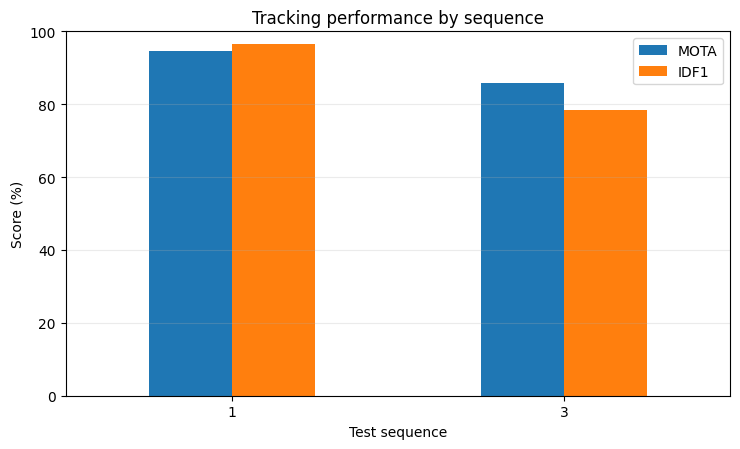

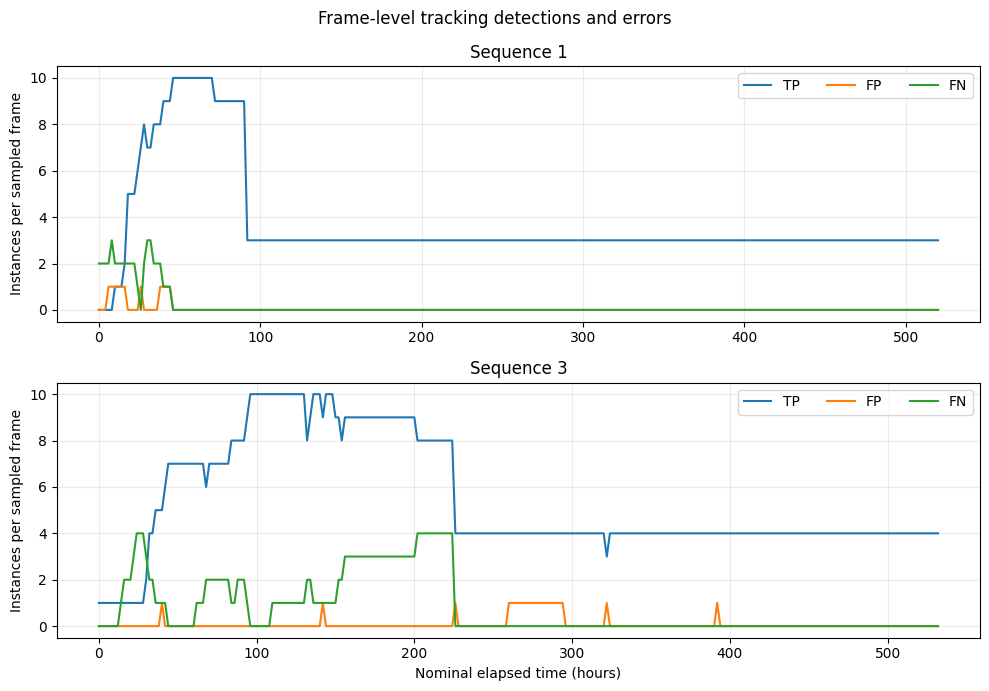

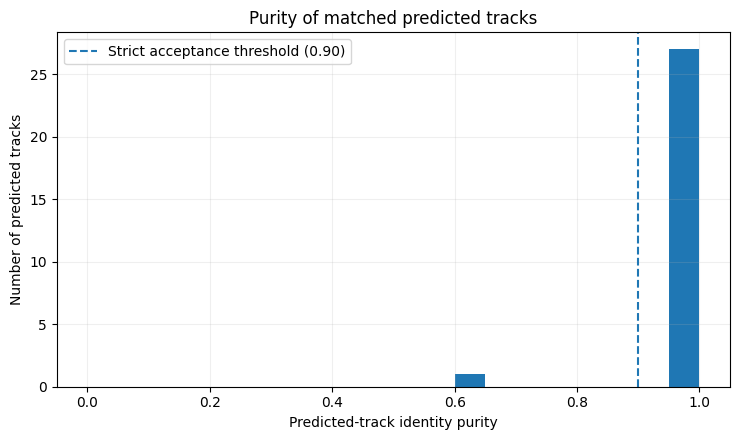

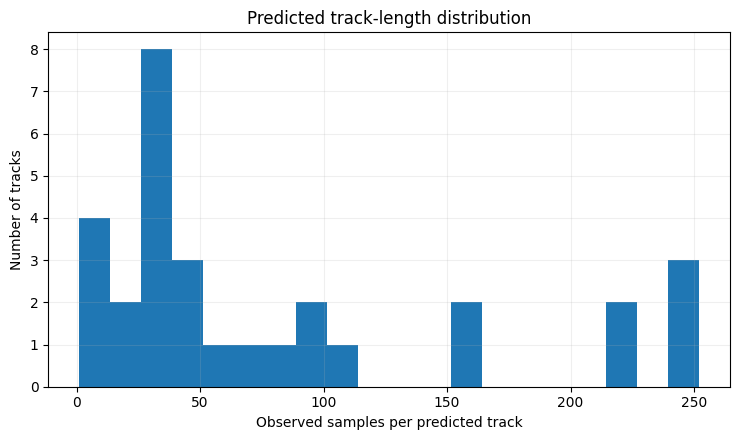

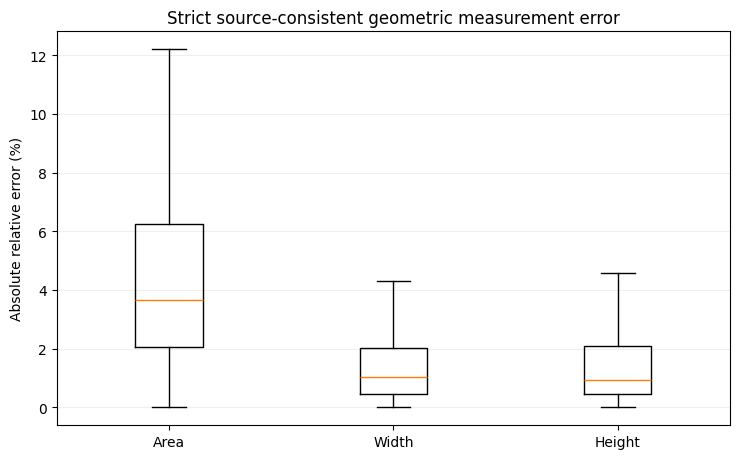

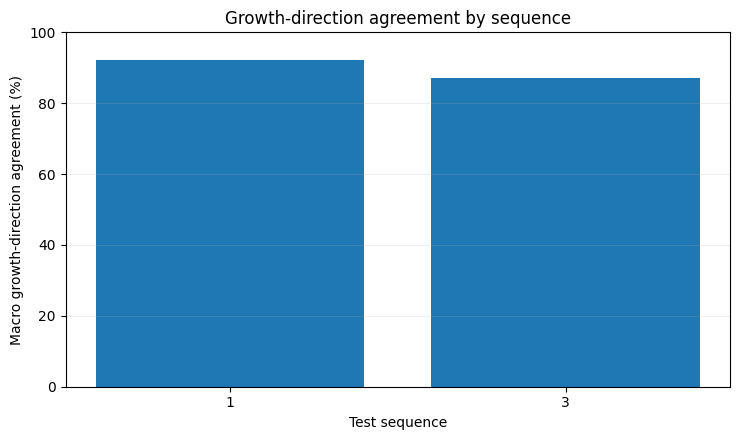

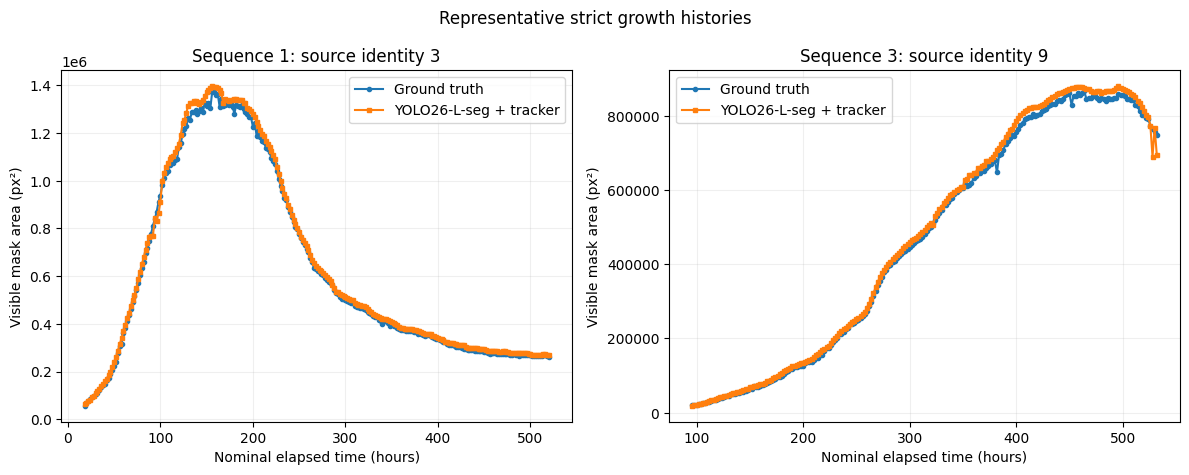

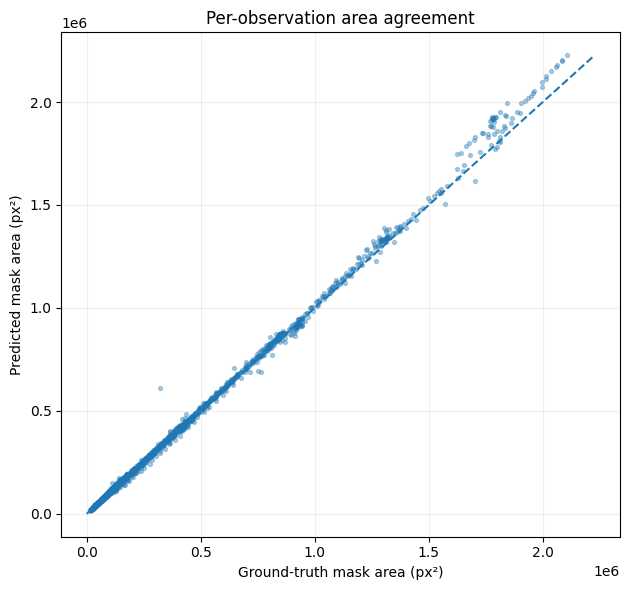

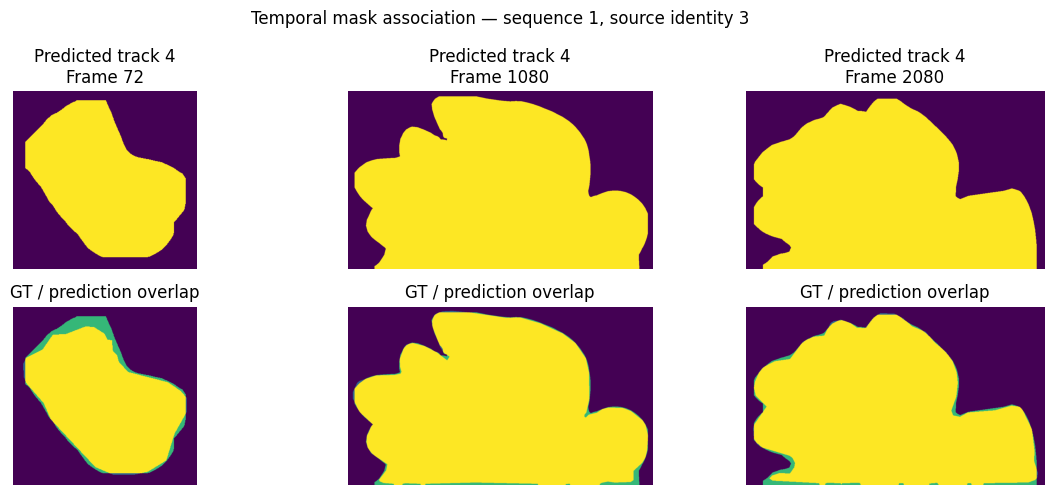

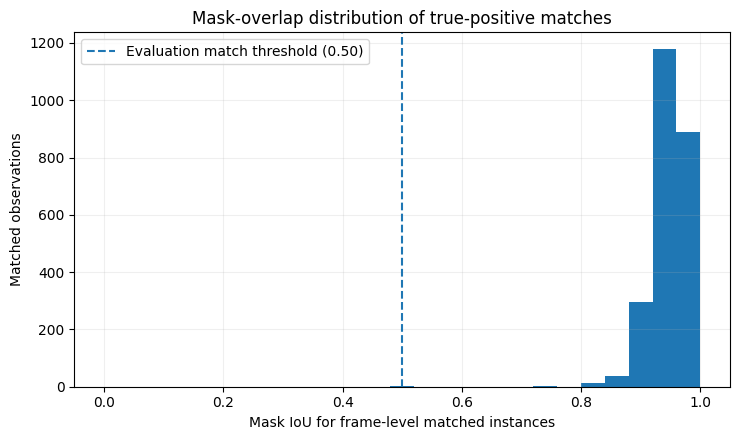

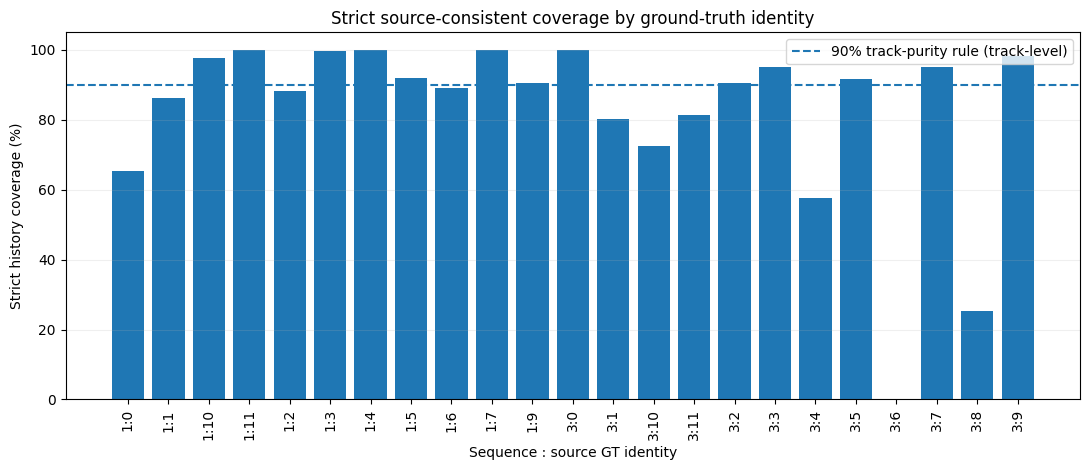

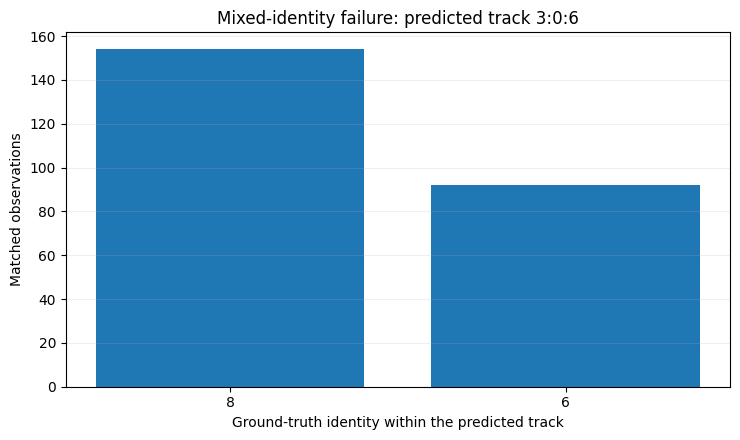

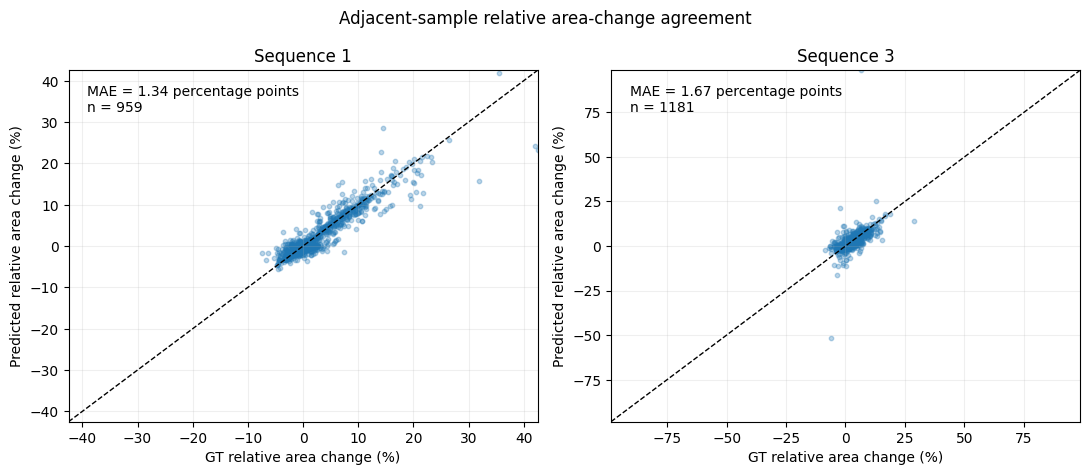

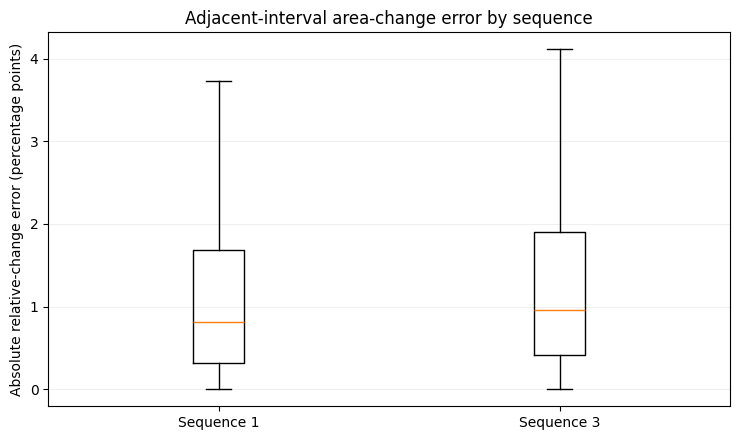

In [14]:
# Figure 1. MOTA and IDF1 by test sequence.
sequence_plot = TEST_PER_SEQUENCE_METRICS.set_index('SEQUENCE_ID')[['MOTA', 'IDF1']] * 100
ax = sequence_plot.plot(kind='bar', figsize=(7.5, 4.6))
ax.set_ylabel('Score (%)')
ax.set_xlabel('Test sequence')
ax.set_title('Tracking performance by sequence')
ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'fig_tracking_mota_idf1_by_sequence.png', dpi=220)
plt.show()

# Figure 2. Per-frame TP, FP, and FN counts over nominal elapsed time.
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=False)
for ax, seq in zip(axes, [1, 3]):
    q = TEST_FRAME_METRICS[TEST_FRAME_METRICS.SEQUENCE_ID == seq].sort_values('ELAPSED_HOURS_NOMINAL')
    ax.plot(q.ELAPSED_HOURS_NOMINAL, q.TP, label='TP')
    ax.plot(q.ELAPSED_HOURS_NOMINAL, q.FP, label='FP')
    ax.plot(q.ELAPSED_HOURS_NOMINAL, q.FN, label='FN')
    ax.set_title(f'Sequence {seq}')
    ax.set_ylabel('Instances per sampled frame')
    ax.grid(alpha=0.25)
    ax.legend(ncol=3)
axes[-1].set_xlabel('Nominal elapsed time (hours)')
fig.suptitle('Frame-level tracking detections and errors')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_frame_level_errors_over_time.png', dpi=220)
plt.show()

# Figure 3. Predicted-track identity purity.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
if len(TEST_TRACK_PURITY_TABLE):
    ax.hist(TEST_TRACK_PURITY_TABLE.TRACK_PURITY.dropna(), bins=np.linspace(0, 1, 21))
ax.axvline(STRICT_PURITY_THRESHOLD, linestyle='--', label='Strict acceptance threshold (0.90)')
ax.set_xlabel('Predicted-track identity purity')
ax.set_ylabel('Number of predicted tracks')
ax.set_title('Purity of matched predicted tracks')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_track_identity_purity.png', dpi=220)
plt.show()

# Figure 4. Predicted track lengths.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
if len(TEST_TRACK_SUMMARY):
    ax.hist(TEST_TRACK_SUMMARY.OBSERVATION_COUNT, bins=20)
ax.set_xlabel('Observed samples per predicted track')
ax.set_ylabel('Number of tracks')
ax.set_title('Predicted track-length distribution')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_track_length_distribution.png', dpi=220)
plt.show()

# Figure 5. Absolute relative error for strict source-consistent measurements.
error_data = [
    np.abs(TEST_STRICT_MATCHES.PRED_AREA_PX.to_numpy(dtype=float) /
           np.maximum(TEST_STRICT_MATCHES.GT_AREA_PX.to_numpy(dtype=float), 1) - 1) * 100,
    np.abs(TEST_STRICT_MATCHES.PRED_WIDTH_PX.to_numpy(dtype=float) /
           np.maximum(TEST_STRICT_MATCHES.GT_WIDTH_PX.to_numpy(dtype=float), 1) - 1) * 100,
    np.abs(TEST_STRICT_MATCHES.PRED_HEIGHT_PX.to_numpy(dtype=float) /
           np.maximum(TEST_STRICT_MATCHES.GT_HEIGHT_PX.to_numpy(dtype=float), 1) - 1) * 100,
]
fig, ax = plt.subplots(figsize=(7.5, 4.7))
ax.boxplot(error_data, tick_labels=['Area', 'Width', 'Height'], showfliers=False)
ax.set_ylabel('Absolute relative error (%)')
ax.set_title('Strict source-consistent geometric measurement error')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_geometric_measurement_error.png', dpi=220)
plt.show()

# Figure 6. Growth-direction agreement by sequence.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
trend = TEST_IDENTITY_GROWTH.groupby('SEQUENCE_ID').TREND_AGREEMENT.mean() * 100
ax.bar(trend.index.astype(str), trend.values)
ax.set_xlabel('Test sequence')
ax.set_ylabel('Macro growth-direction agreement (%)')
ax.set_ylim(0, 100)
ax.set_title('Growth-direction agreement by sequence')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_growth_direction_agreement.png', dpi=220)
plt.show()

# Figure 7. Representative long strict tracklets; selection is by observation count only.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
representative_tracks = []
for ax, seq in zip(axes, [1, 3]):
    q = TEST_STRICT_MATCHES[TEST_STRICT_MATCHES.SEQUENCE_ID == seq]
    if q.empty:
        ax.set_title(f'Sequence {seq}: no strict matched histories')
        continue
    lens = q.groupby(['GT_TRACK_KEY', 'PRED_TRACK_KEY']).size().sort_values(ascending=False)
    gt_key, pred_key = lens.index[0]
    track = q[(q.GT_TRACK_KEY == gt_key) & (q.PRED_TRACK_KEY == pred_key)].sort_values('ELAPSED_MINUTES_NOMINAL')
    x = track.ELAPSED_MINUTES_NOMINAL.to_numpy(dtype=float) / 60.0
    ax.plot(x, track.GT_AREA_PX, marker='o', markersize=3, label='Ground truth')
    ax.plot(x, track.PRED_AREA_PX, marker='s', markersize=3, label='YOLO26-L-seg + tracker')
    ax.set_title(f'Sequence {seq}: source identity {gt_key.split(":")[-1]}')
    ax.set_xlabel('Nominal elapsed time (hours)')
    ax.set_ylabel('Visible mask area (px²)')
    ax.grid(alpha=0.2)
    ax.legend()
    representative_tracks.append({
        'SEQUENCE_ID': seq, 'GT_TRACK_KEY': gt_key, 'PRED_TRACK_KEY': pred_key,
        'OBSERVATIONS': len(track)
    })
fig.suptitle('Representative strict growth histories')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_representative_growth_trajectories.png', dpi=220)
plt.show()
pd.DataFrame(representative_tracks).to_csv(OUTPUT_DIR / 'representative_growth_trajectories.csv', index=False)

# Figure 8. Per-observation area agreement.
fig, ax = plt.subplots(figsize=(6.4, 6.0))
if len(TEST_STRICT_MATCHES):
    x = TEST_STRICT_MATCHES.GT_AREA_PX.to_numpy(dtype=float)
    y = TEST_STRICT_MATCHES.PRED_AREA_PX.to_numpy(dtype=float)
    ax.scatter(x, y, s=8, alpha=0.35)
    maxv = max(float(np.max(x)), float(np.max(y)))
    ax.plot([0, maxv], [0, maxv], linestyle='--')
ax.set_xlabel('Ground-truth mask area (px²)')
ax.set_ylabel('Predicted mask area (px²)')
ax.set_title('Per-observation area agreement')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_area_measurement_agreement.png', dpi=220)
plt.show()

# Figure 9. Temporal mask correspondence for the longest strict predicted tracklet.
def decode_binary_mask(rle):
    counts = decode_coco_compressed_counts(rle)
    h, w = map(int, rle['size'])
    flat = np.zeros(h * w, dtype=np.uint8)
    cursor = 0
    foreground = 0
    for run in counts:
        end = min(cursor + int(run), flat.size)
        if foreground and end > cursor:
            flat[cursor:end] = 1
        cursor = end
        foreground = 1 - foreground
    return flat.reshape((h, w), order='F')

if len(TEST_STRICT_MATCHES):
    sizes = TEST_STRICT_MATCHES.groupby(['SEQUENCE_ID','GT_TRACK_KEY','PRED_TRACK_KEY']).size().sort_values(ascending=False)
    (seq, gt_key, pred_key), _ = sizes.index[0], int(sizes.iloc[0])
    tracklet = TEST_STRICT_MATCHES[
        (TEST_STRICT_MATCHES.SEQUENCE_ID == seq) &
        (TEST_STRICT_MATCHES.GT_TRACK_KEY == gt_key) &
        (TEST_STRICT_MATCHES.PRED_TRACK_KEY == pred_key)
    ].sort_values('FRAME_ID')
    positions = np.unique(np.linspace(0, len(tracklet)-1, min(3, len(tracklet))).round().astype(int))
    chosen = tracklet.iloc[positions]
    fig, axes = plt.subplots(2, len(chosen), figsize=(4 * len(chosen), 5))
    if len(chosen) == 1:
        axes = np.asarray(axes).reshape(2, 1)
    for col, row in enumerate(chosen.to_dict('records')):
        fr = RECORD_BY_KEY[str(row['FRAME_KEY'])]
        pred = fr['PREDICTIONS'][int(row['FRAME_INSTANCE_ID'])]
        gt = fr['GROUND_TRUTH_INSTANCES'][int(row['GT_FRAME_INSTANCE_ID'])]
        pm = decode_binary_mask(pred['MASK_RLE'])
        gm = decode_binary_mask(gt['MASK_RLE'])
        x0 = min(int(pred['BBOX_XYXY'][0]), int(gt['BBOX_XYXY'][0]))
        y0 = min(int(pred['BBOX_XYXY'][1]), int(gt['BBOX_XYXY'][1]))
        x1 = max(int(pred['BBOX_XYXY'][2]), int(gt['BBOX_XYXY'][2]))
        y1 = max(int(pred['BBOX_XYXY'][3]), int(gt['BBOX_XYXY'][3]))
        pad = 20
        x0=max(0,x0-pad); y0=max(0,y0-pad)
        x1=min(pm.shape[1],x1+pad); y1=min(pm.shape[0],y1+pad)
        combined = gm[y0:y1,x0:x1].astype(np.uint8) + 2 * pm[y0:y1,x0:x1].astype(np.uint8)
        axes[0,col].imshow(pm[y0:y1,x0:x1])
        axes[0,col].set_title(f'Predicted track {str(pred_key).split(":")[-1]}\nFrame {row["FRAME_ID"]}')
        axes[1,col].imshow(combined)
        axes[1,col].set_title('GT / prediction overlap')
        axes[0,col].axis('off'); axes[1,col].axis('off')
    fig.suptitle(f'Temporal mask association — sequence {seq}, source identity {str(gt_key).split(":")[-1]}')
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / 'fig_temporal_mask_association_progression.png', dpi=220)
    plt.show()


# Figure 10. Mask IoU distribution for accepted frame-level TP matches.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
if len(TEST_MATCHES):
    ax.hist(TEST_MATCHES.MASK_IOU, bins=np.linspace(0, 1, 26))
ax.axvline(MASK_MATCH_IOU, linestyle='--', label=f'Evaluation match threshold ({MASK_MATCH_IOU:.2f})')
ax.set_xlabel('Mask IoU for frame-level matched instances')
ax.set_ylabel('Matched observations')
ax.set_title('Mask-overlap distribution of true-positive matches')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_matched_mask_iou_distribution.png', dpi=220)
plt.show()

# Figure 11. Strict source-consistent coverage for each annotated identity.
fig, ax = plt.subplots(figsize=(11, 4.8))
coverage_plot = TEST_IDENTITY_COVERAGE_TABLE.sort_values(['SEQUENCE_ID', 'GT_TRACK_ID']).copy()
tick_names = [f'{int(r.SEQUENCE_ID)}:{r.GT_TRACK_ID}' for r in coverage_plot.itertuples(index=False)]
ax.bar(np.arange(len(coverage_plot)), coverage_plot.STRICT_COVERAGE * 100)
ax.axhline(90, linestyle='--', label='90% track-purity rule (track-level)')
ax.set_xticks(np.arange(len(coverage_plot)))
ax.set_xticklabels(tick_names, rotation=90)
ax.set_xlabel('Sequence : source GT identity')
ax.set_ylabel('Strict history coverage (%)')
ax.set_ylim(0, 105)
ax.set_title('Strict source-consistent coverage by ground-truth identity')
ax.grid(axis='y', alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_strict_history_coverage_by_identity.png', dpi=220)
plt.show()

# Figure 12. Composition of a predicted track that failed the whole-track purity rule.
mixed = TEST_TRACK_PURITY_TABLE[TEST_TRACK_PURITY_TABLE.GT_IDENTITIES_MIXED > 1]
if len(mixed):
    failed_key = str(mixed.sort_values('TRACK_PURITY').iloc[0].PRED_TRACK_KEY)
    composition = TEST_MATCHES[TEST_MATCHES.PRED_TRACK_KEY == failed_key].GT_TRACK_KEY.value_counts().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.bar([x.split(':')[-1] for x in composition.index], composition.values)
    ax.set_xlabel('Ground-truth identity within the predicted track')
    ax.set_ylabel('Matched observations')
    ax.set_title(f'Mixed-identity failure: predicted track {failed_key}')
    ax.grid(axis='y', alpha=0.2)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / 'fig_mixed_identity_track_failure.png', dpi=220)
    plt.show()


# Figure 13. Adjacent-interval relative area-change agreement.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, seq in zip(axes, [1, 3]):
    q = TEST_AREA_CHANGE_TRANSITIONS[TEST_AREA_CHANGE_TRANSITIONS.SEQUENCE_ID == seq]
    if len(q):
        x = q.GT_RELATIVE_AREA_CHANGE.to_numpy(dtype=float) * 100
        y = q.PRED_RELATIVE_AREA_CHANGE.to_numpy(dtype=float) * 100
        lim = max(float(np.max(np.abs(x))), float(np.max(np.abs(y))), 5.0)
        ax.scatter(x, y, s=10, alpha=0.30)
        ax.plot([-lim, lim], [-lim, lim], linestyle='--', color='black', linewidth=1)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        mae = q.ABSOLUTE_RELATIVE_AREA_CHANGE_ERROR.mean() * 100
        ax.text(0.04, 0.96, f'MAE = {mae:.2f} percentage points\nn = {len(q)}',
                transform=ax.transAxes, va='top', ha='left')
    ax.set_title(f'Sequence {seq}')
    ax.set_xlabel('GT relative area change (%)')
    ax.set_ylabel('Predicted relative area change (%)')
    ax.grid(alpha=0.2)
fig.suptitle('Adjacent-sample relative area-change agreement')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_adjacent_relative_area_change_agreement.png', dpi=220)
plt.show()

# Figure 14. Absolute adjacent-interval area-change error by sequence.
error_by_sequence = [
    TEST_AREA_CHANGE_TRANSITIONS.loc[TEST_AREA_CHANGE_TRANSITIONS.SEQUENCE_ID == seq,
        'ABSOLUTE_RELATIVE_AREA_CHANGE_ERROR'].to_numpy(dtype=float) * 100
    for seq in [1, 3]
]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.boxplot(error_by_sequence, tick_labels=['Sequence 1', 'Sequence 3'], showfliers=False)
ax.set_ylabel('Absolute relative-change error (percentage points)')
ax.set_title('Adjacent-interval area-change error by sequence')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'fig_adjacent_area_change_error_by_sequence.png', dpi=220)
plt.show()


## 11. Contextual comparison with Charisis et al.

The published Charisis MOTA values are included as context only. The MOTA equation is the same, but these values are not a controlled head-to-head comparison: the detector, frame sequences, preprocessing, filtering, tracking implementation, and experimental conditions differ.

Charisis reports MOTA of 0.967 on sequence 1 and 0.927 on sequence 3 of its own dataset. FungiCirno reports MOTA on its own test sequences 1 and 3. Matching sequence labels do not imply that the underlying image sequences are the same. The comparison table therefore identifies the Charisis values as published references and the FungiCirno values as current results, without ranking the methods as though they were evaluated on common data.

The two systems share a mask-overlap association principle. FungiCirno uses YOLO26-L-seg masks and Hungarian one-to-one assignment with a 0.10 association IoU threshold. The frame-level evaluation uses a separate 0.50 mask-IoU threshold. FungiCirno retains a track only when its next sampled observation is associated within the configured zero-gap policy; it does not maintain a long-lived unmatched baseline for later recovery. The reference method includes its own domain-specific filtering and tracking procedures. These differences should be considered when interpreting the reported metrics.


In [15]:
CHARISIS_CONTEXT = pd.DataFrame([
    {'METHOD': 'Charisis et al. (2025)', 'SEQUENCE_ID': 1, 'MOTA': 0.967,
     'NOTE': 'Published result; contextual reference, not a controlled comparison.'},
    {'METHOD': 'Charisis et al. (2025)', 'SEQUENCE_ID': 3, 'MOTA': 0.927,
     'NOTE': 'Published result; contextual reference, not a controlled comparison.'},
    *[
        {'METHOD': 'FungiCirno YOLO26-L-seg + frozen tracker',
         'SEQUENCE_ID': int(r.SEQUENCE_ID), 'MOTA': float(r.MOTA),
         'NOTE': 'Current test evaluation; model and evaluation protocol differ.'}
        for r in TEST_PER_SEQUENCE_METRICS.itertuples(index=False)
    ],
])
CHARISIS_CONTEXT.to_csv(OUTPUT_DIR / 'charisis_contextual_mota_comparison.csv', index=False)
display(CHARISIS_CONTEXT)

,METHOD,SEQUENCE_ID,MOTA,NOTE
0,Charisis et al. (2025),1,0.967000,"Published result; contextual reference, not a ..."
1,Charisis et al. (2025),3,0.927000,"Published result; contextual reference, not a ..."
2,FungiCirno YOLO26-L-seg + frozen tracker,1,0.945759,Current test evaluation; model and evaluation ...
3,FungiCirno YOLO26-L-seg + frozen tracker,3,0.858702,Current test evaluation; model and evaluation ...


## 12. Reproducibility and exported evidence

The output archive contains the frozen configuration, overall and per-sequence metrics, frame-level detections, frame matches, track summaries, track purity, source-identity coverage, strict growth measurements, reassociation audits, publication figures, a run manifest, and an integrity report.

The tracking runtime is reported separately from model inference. The latter is recorded by `full-inference.ipynb` and is not repeated in this notebook.

In [16]:
# Export the complete tracking and growth-history evidence.
TEST_OVERALL_METRICS.to_csv(OUTPUT_DIR / 'test_overall_metrics.csv', index=False)
TEST_PER_SEQUENCE_METRICS.to_csv(OUTPUT_DIR / 'test_per_sequence_metrics.csv', index=False)
TEST_FRAME_METRICS.to_csv(OUTPUT_DIR / 'test_frame_metrics.csv', index=False)
TEST_MATCHES.to_csv(OUTPUT_DIR / 'test_frame_matches.csv', index=False)
TEST_GT_STATES.to_csv(OUTPUT_DIR / 'test_ground_truth_identity_states.csv', index=False)
TEST_TRACK_PURITY_TABLE.to_csv(OUTPUT_DIR / 'test_track_purity.csv', index=False)
TEST_IDENTITY_COVERAGE_TABLE.to_csv(OUTPUT_DIR / 'test_source_identity_coverage.csv', index=False)
TEST_STRICT_MATCHES.to_csv(OUTPUT_DIR / 'test_strict_growth_observations.csv', index=False)
TEST_IDENTITY_GROWTH.to_csv(OUTPUT_DIR / 'test_growth_metrics_by_identity.csv', index=False)
TEST_TRACK_SUMMARY.to_csv(OUTPUT_DIR / 'test_track_summaries.csv', index=False)
TEST_TRACK_EVENTS.to_csv(OUTPUT_DIR / 'test_track_events.csv', index=False)
TEST_REASSOCIATION_AUDIT.to_csv(OUTPUT_DIR / 'test_reassociation_audit.csv', index=False)
TRACK_RESULT['observations'].to_csv(OUTPUT_DIR / 'test_tracked_observations.csv', index=False)
CHARISIS_CONTEXT.to_csv(OUTPUT_DIR / 'charisis_contextual_mota_comparison.csv', index=False)

confidence_rows = []
for seq in [1, 3]:
    predictions = [d for fr in records if int(fr['SEQUENCE_ID']) == seq for d in fr['PREDICTIONS']]
    confidence_rows.append({
        'SEQUENCE_ID': seq,
        'RAW_PREDICTION_CANDIDATES': len(predictions),
        'CANDIDATES_ABOVE_CONFIDENCE_FLOOR': int(sum(float(d['CONFIDENCE']) >= TRACKER_CONFIG['CONFIDENCE_FLOOR'] for d in predictions)),
        'CANDIDATES_ABOVE_HIGH_THRESHOLD': int(sum(float(d['CONFIDENCE']) >= EXPECTED_HIGH for d in predictions)),
        'TRACKED_OBSERVATIONS': int((TRACK_RESULT['observations'].SEQUENCE_ID == seq).sum()),
        'LOW_CONFIDENCE_RECOVERY_OBSERVATIONS': int(((TRACK_RESULT['observations'].SEQUENCE_ID == seq) &
            (TRACK_RESULT['observations'].ASSOCIATION_STAGE == 'low_confidence_recovery')).sum()),
    })
TEST_CONFIDENCE_COUNTS = pd.DataFrame(confidence_rows)
TEST_CONFIDENCE_COUNTS.to_csv(OUTPUT_DIR / 'test_confidence_operating_point.csv', index=False)

# Explicit identity-failure tables for the paper's error analysis.
mixed_rows = []
for p in TEST_TRACK_PURITY_TABLE[TEST_TRACK_PURITY_TABLE.GT_IDENTITIES_MIXED > 1].itertuples(index=False):
    matched = TEST_MATCHES[TEST_MATCHES.PRED_TRACK_KEY == p.PRED_TRACK_KEY]
    identity_counts = matched.GT_TRACK_KEY.value_counts()
    ordered_ids = list(identity_counts.items())
    mixed_rows.append({
        'SEQUENCE_ID': int(p.SEQUENCE_ID), 'PRED_TRACK_KEY': str(p.PRED_TRACK_KEY),
        'MATCHED_OBSERVATIONS': int(p.MATCHED_OBSERVATIONS),
        'GT_IDENTITIES_MIXED': int(p.GT_IDENTITIES_MIXED),
        'DOMINANT_GT_TRACK_KEY': str(ordered_ids[0][0]), 'DOMINANT_MATCHES': int(ordered_ids[0][1]),
        'SECONDARY_GT_TRACKS': json.dumps([{'GT_TRACK_KEY': str(k), 'MATCHES': int(v)} for k,v in ordered_ids[1:]]),
        'TRACK_PURITY': float(p.TRACK_PURITY),
        'STRICT_HISTORY_ACTION': 'exclude entire predicted track',
    })
MIXED_TRACK_FAILURES = pd.DataFrame(mixed_rows)
MIXED_TRACK_FAILURES.to_csv(OUTPUT_DIR / 'test_mixed_identity_track_failures.csv', index=False)

UNAVAILABLE_IDENTITY_HISTORIES = TEST_IDENTITY_COVERAGE_TABLE[
    TEST_IDENTITY_COVERAGE_TABLE.STRICT_MATCHED_OBSERVATIONS == 0
].copy()
UNAVAILABLE_IDENTITY_HISTORIES.to_csv(OUTPUT_DIR / 'test_source_identities_without_strict_history.csv', index=False)

fragment_rows = []
if len(TEST_MATCHES):
    for gt_key, grp in TEST_MATCHES.groupby('GT_TRACK_KEY'):
        pred_keys = sorted(set(grp.PRED_TRACK_KEY.astype(str)))
        if len(pred_keys) > 1:
            fragment_rows.append({'SEQUENCE_ID': int(grp.SEQUENCE_ID.iloc[0]), 'GT_TRACK_KEY': str(gt_key),
                                  'MATCHED_OBSERVATIONS': int(len(grp)), 'PREDICTED_TRACK_COUNT': len(pred_keys),
                                  'PREDICTED_TRACK_KEYS': json.dumps(pred_keys)})
FRAGMENTED_GT_IDENTITIES = pd.DataFrame(fragment_rows)
FRAGMENTED_GT_IDENTITIES.to_csv(OUTPUT_DIR / 'test_fragmented_source_identities.csv', index=False)

(OUTPUT_DIR / 'selected_tracker_config_v5.json').write_text(
    json.dumps(FROZEN_TRACKER_CONFIG, indent=2, sort_keys=True), encoding='utf-8')
(OUTPUT_DIR / 'selected_tracker_config_v5.sha256').write_text(
    FROZEN_TRACKER_CONFIG_SHA256 + '  selected_tracker_config_v5.json\n', encoding='utf-8')

def sha256_file_for_manifest(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

source_manifest_hash = SOURCE_MANIFEST_RAW_SHA256
raw_cache_hash = YOLO_CACHE_RAW_SHA256
member_fingerprint = BUNDLE_MEMBER_FINGERPRINT_SHA256

overall_row = TEST_OVERALL_METRICS.iloc[0].to_dict()
per_sequence_json = TEST_PER_SEQUENCE_METRICS.to_dict(orient='records')
run_manifest = {
    'notebook': FINAL_EVALUATION_NOTEBOOK,
    'paper_title': PAPER_TITLE,
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'input_evidence_path': str(BUNDLE_PATH),
    'input_archive_sha256': BUNDLE_SHA256,
    'input_evidence_member_fingerprint_sha256': member_fingerprint,
    'source_inference_created_utc': SOURCE_RUN_MANIFEST.get('created_utc'),
    'source_inference_notebook_filename_as_recorded_in_source_manifest': SOURCE_NOTEBOOK_FILENAME_AS_RECORDED,
    'current_project_full_inference_notebook_filename': SOURCE_NOTEBOOK_FILENAME_CURRENT,
    'source_notebook_filename_note': (
        'The original inference manifest retains its recorded notebook name. '
        'The current project filename supplied for the inference stage is full-inference.ipynb. '
        'Both values are retained; the original source manifest is not rewritten.'
    ),
    'source_manifest_raw_sha256': source_manifest_hash,
    'source_yolo_prediction_cache_raw_sha256': YOLO_CACHE_RAW_SHA256,
    'source_maskrcnn_prediction_cache_raw_sha256': MASKRCNN_CACHE_RAW_SHA256,
    'test_prediction_records_canonical_sha256': TEST_CACHE_SHA256,
    'dataset_scope': 'test_only',
    'test_frames': len(records),
    'test_sequence_counts': test_sequence_counts,
    'ground_truth_observations': int(TEST_SUMMARY['GT_DETECTIONS']),
    'tracker_configuration_name': TRACKER_CONFIG['NAME'],
    'tracker_configuration_sha256': FROZEN_TRACKER_CONFIG_SHA256,
    'tracker_parameters': {k: v for k, v in TRACKER_CONFIG.items() if k != 'NAME'},
    'track_association_iou_threshold': float(TRACKER_CONFIG['ASSOCIATION_IOU']),
    'evaluation_mask_iou_threshold': MASK_MATCH_IOU,
    'strict_track_purity_threshold': STRICT_PURITY_THRESHOLD,
    'test_sample_stride_source_frames': TEST_SAMPLE_STRIDE,
    'nominal_source_cadence_minutes': SOURCE_CADENCE_MINUTES,
    'nominal_evaluation_interval_hours': NOMINAL_SAMPLE_INTERVAL_HOURS,
    'measurements_are_image_space_only': True,
    'physical_scale_calibration_applied': False,
    'model_inference_rerun': False,
    'test_parameter_tuning': False,
    'mixed_identity_predicted_tracks': int(len(MIXED_TRACK_FAILURES)),
    'source_identities_without_strict_histories': int(len(UNAVAILABLE_IDENTITY_HISTORIES)),
    'fragmented_source_identities': int(len(FRAGMENTED_GT_IDENTITIES)),
    'tracker_runtime_seconds': TRACKER_RUNTIME_SECONDS,
    'tracker_runtime_ms_per_frame': TRACKER_RUNTIME_SECONDS * 1000 / len(records),
    'evaluation_runtime_seconds': EVALUATION_RUNTIME_SECONDS,
    'python_version': platform.python_version(),
    'platform': platform.platform(),
    'numpy_version': np.__version__,
    'pandas_version': pd.__version__,
    'matplotlib_version': plt.matplotlib.__version__,
    'numba_available': NUMBA_AVAILABLE,
    'overall_metrics': overall_row,
    'per_sequence_metrics': per_sequence_json,
    'metric_interpretation': {
        'strict_pooled_coverage': 'Strict matched observations divided by all GT observations.',
        'strict_macro_coverage': 'Unweighted mean of per-source-identity coverage, including identities with zero strict observations.',
        'normalized_relative_area_trajectory_mae_unitless': 'Mean absolute difference between independently first-observation-normalized predicted and GT area trajectories; unitless supplementary diagnostic, not RAE or a percentage.',
        'adjacent_relative_area_change_mae': 'Mean absolute difference between predicted and GT relative area change over consecutive sampled observations within one accepted predicted tracklet.',
        'growth_direction_agreement': 'Macro-average of per-identity agreement among increase/stable/decrease categories using a 5% deadband.'
    }
}
(OUTPUT_DIR / 'tracking_evaluation_run_manifest.json').write_text(
    json.dumps(run_manifest, indent=2, default=str), encoding='utf-8')

integrity_checks = {
    'test_frame_count_528': len(records) == 528,
    'test_sequence_counts_are_1_261_and_3_267': test_sequence_counts == {1: 261, 3: 267},
    'all_records_test_split': all(str(r.get('SPLIT', '')).lower() == 'test' for r in records),
    'all_test_ground_truth_instances_have_track_ids': all(
        g.get('GT_TRACK_ID') is not None for fr in records for g in fr['GROUND_TRUTH_INSTANCES']),
    'all_prediction_rle_dimensions_and_areas_validated': True,
    'all_gt_rle_dimensions_and_areas_validated': True,
    'frozen_tracker_configuration_hash_verified': _actual_config_hash == FROZEN_TRACKER_CONFIG_SHA256,
    'source_manifest_raw_hash_present': len(SOURCE_MANIFEST_RAW_SHA256) == 64,
    'source_yolo_cache_raw_hash_present': len(YOLO_CACHE_RAW_SHA256) == 64,
    'no_model_inference_executed': True,
    'no_test_parameter_tuning_executed': True,
    'mota_recomputed_from_counts': abs(float(overall_row['MOTA_CUSTOM_FRAME_MATCH']) -
        (1.0 - (int(overall_row['DETECTION_FP']) + int(overall_row['DETECTION_FN']) + int(overall_row['IDSW'])) /
         max(int(overall_row['GT_DETECTIONS']), 1))) < 1e-12,
    'idf1_recomputed_from_id_counts': abs(float(overall_row['IDF1']) -
        (2 * int(overall_row['IDTP']) / max(2 * int(overall_row['IDTP']) + int(overall_row['IDFP']) + int(overall_row['IDFN']), 1))) < 1e-12,
    'strict_growth_observation_count_consistent': int(overall_row['STRICT_MATCHED_OBSERVATIONS']) == len(TEST_STRICT_MATCHES),
    'adjacent_area_change_transition_count_consistent': int(overall_row['ADJACENT_AREA_CHANGE_TRANSITIONS']) == len(TEST_AREA_CHANGE_TRANSITIONS),
    'image_space_measurement_limitation_recorded': run_manifest['physical_scale_calibration_applied'] is False,
}
integrity = {'status': 'PASS' if all(integrity_checks.values()) else 'FAIL', 'checks': integrity_checks}
if integrity['status'] != 'PASS':
    raise RuntimeError('Evidence integrity checks failed.')
(OUTPUT_DIR / 'integrity_report.json').write_text(json.dumps(integrity, indent=2), encoding='utf-8')

metric_definitions = f'''# Metric definitions and interpretation

## Tracking

- **MOTA:** `1 - (FP + FN + IDSW) / GT`, with one-to-one frame-level mask-IoU matching at {MASK_MATCH_IOU:.2f}.
- **IDF1:** global identity-assignment F1 calculated from IDTP, IDFP and IDFN.
- **Association IoU:** {TRACKER_CONFIG['ASSOCIATION_IOU']:.2f}. This is a tracker parameter and is not the frame-level evaluation threshold.

## Strict source-consistent histories

A predicted track is accepted only if at least {STRICT_PURITY_THRESHOLD:.0%} of its matched observations belong to its dominant GT identity. A failed track is excluded as a whole. Pooled coverage is based on all GT observations; macro coverage averages coverage across source identities, including the identity with no accepted history.

## Geometric measurement

Pooled RAE is `100/N * sum(abs(predicted - GT) / max(GT, 1))`. It is computed for area, width and height on strict matched observations. The measurements are image-space px or px²; no physical-scale calibration was applied.

## Temporal area measurements

- **Adjacent relative-area-change MAE:** mean absolute difference between predicted and GT relative area changes over consecutive sampled observations within the same accepted predicted tracklet. The pooled value is {overall_row['ADJACENT_RELATIVE_AREA_CHANGE_MAE_POOLED']:.6f} (1.52 percentage points); the macro value is {overall_row['ADJACENT_RELATIVE_AREA_CHANGE_MAE_MACRO']:.6f} (1.76 percentage points) over {int(overall_row['ADJACENT_AREA_CHANGE_TRANSITIONS'])} transitions.
- **Growth-direction agreement:** per-identity agreement for increase/stable/decrease categories with a 5% deadband, macro-averaged over eligible identities.
- **Normalized relative-area trajectory MAE:** {overall_row['NORMALIZED_RELATIVE_AREA_TRAJECTORY_MAE_UNITLESS_MACRO']:.6f}, a unitless difference between independently normalized trajectories. It is supplementary and is not reported as a percentage or a relative absolute error.
'''
(OUTPUT_DIR / 'METRIC_DEFINITIONS.md').write_text(metric_definitions, encoding='utf-8')

figure_captions = '''# Figure captions

1. **Tracking performance by sequence** (`fig_tracking_mota_idf1_by_sequence.png`). MOTA and IDF1 on test sequences 1 and 3, calculated using the frozen tracker and the stated evaluation protocol.
2. **Frame-level tracking detections and errors** (`fig_frame_level_errors_over_time.png`). True positives, false positives and false negatives per sampled test frame, plotted against nominal elapsed time.
3. **Purity of matched predicted tracks** (`fig_track_identity_purity.png`). Distribution of predicted-track source-identity purity; the dashed line indicates the 90% whole-track strict-history threshold.
4. **Predicted track-length distribution** (`fig_track_length_distribution.png`). Number of sampled observations assigned to each predicted track.
5. **Strict source-consistent geometric measurement error** (`fig_geometric_measurement_error.png`). Absolute relative error in area, width and height on observations retained after whole-track purity filtering.
6. **Growth-direction agreement by sequence** (`fig_growth_direction_agreement.png`). Macro agreement of increase/stable/decrease classifications across source identities with eligible adjacent observations.
7. **Representative strict growth histories** (`fig_representative_growth_trajectories.png`). Predicted and annotated visible mask area for one long accepted tracklet in each test sequence.
8. **Per-observation area agreement** (`fig_area_measurement_agreement.png`). Predicted versus annotated mask area on strict matched observations; values are image-space px².
9. **Temporal mask association progression** (`fig_temporal_mask_association_progression.png`). Predicted mask silhouettes and GT/prediction overlap at three observations of one accepted tracklet. This figure shows masks only, not original RGB frames.
10. **Matched mask-IoU distribution** (`fig_matched_mask_iou_distribution.png`). Mask IoU for frame-level TP matches, with the 0.50 evaluation threshold.
11. **Strict source-consistent coverage by identity** (`fig_strict_history_coverage_by_identity.png`). Coverage for each annotated source identity after whole-track purity filtering.
12. **Mixed-identity track failure** (`fig_mixed_identity_track_failure.png`). Composition of the predicted track excluded in full because its source-identity purity fell below 90%.
13. **Adjacent-interval relative-area-change agreement** (`fig_adjacent_relative_area_change_agreement.png`). Predicted versus annotated relative area change between consecutive sampled observations within the same accepted tracklet; the diagonal denotes exact agreement.
14. **Adjacent-interval area-change error by sequence** (`fig_adjacent_area_change_error_by_sequence.png`). Distribution of absolute error in relative area change, expressed in percentage points, for each sequence.
'''
(OUTPUT_DIR / 'FIGURE_CAPTIONS.md').write_text(figure_captions, encoding='utf-8')

# Dynamic README derived from the evaluated outputs.
seq_lines = []
for r in TEST_PER_SEQUENCE_METRICS.itertuples(index=False):
    seq_lines.append(f"| {int(r.SEQUENCE_ID)} | {int(r.FRAMES)} | {int(r.GT_OBSERVATIONS)} | {r.MOTA:.2%} | {r.IDF1:.2%} | {int(r.IDSW)} | {int(r.FN)} |")
readme = f'''# Tracking and growth-history evaluation

**Paper:** *{PAPER_TITLE}*

## Evaluation scope

This is the downstream tracking/measurement notebook. It consumes the cached YOLO26-L-seg prediction records from `{CURRENT_FULL_INFERENCE_NOTEBOOK}` and does not rerun model inference or repeat segmentation evaluation.

- Test frames: **{len(records)}** (sequence 1: 261; sequence 3: 267).
- Ground-truth observations: **{int(TEST_SUMMARY['GT_DETECTIONS'])}**.
- Frozen tracker: `{TRACKER_CONFIG['NAME']}`.
- Tracker configuration SHA-256: `{FROZEN_TRACKER_CONFIG_SHA256}`.
- Association IoU: **{TRACKER_CONFIG['ASSOCIATION_IOU']:.2f}**; frame-level evaluation IoU: **{MASK_MATCH_IOU:.2f}**.
- Nominal evaluation interval: **{NOMINAL_SAMPLE_INTERVAL_HOURS:.1f} hours**.
- Model inference rerun: **No**; test parameter tuning: **No**.

## Overall test results

| Metric | Result |
|---|---:|
| MOTA | {overall_row['MOTA_CUSTOM_FRAME_MATCH']:.2%} |
| IDF1 | {overall_row['IDF1']:.2%} |
| Detection precision / recall / F1 | {overall_row['DETECTION_PRECISION']:.2%} / {overall_row['DETECTION_RECALL']:.2%} / {overall_row['DETECTION_F1']:.2%} |
| TP / FP / FN / ID switches | {int(overall_row['DETECTION_TP'])} / {int(overall_row['DETECTION_FP'])} / {int(overall_row['DETECTION_FN'])} / {int(overall_row['IDSW'])} |
| Strict pooled / macro history coverage | {overall_row['STRICT_POOLED_COVERAGE']:.2%} / {overall_row['STRICT_MACRO_COVERAGE']:.2%} |
| Pooled area / width / height RAE | {overall_row['STRICT_AREA_RAE_POOLED']:.2%} / {overall_row['STRICT_WIDTH_RAE_POOLED']:.2%} / {overall_row['STRICT_HEIGHT_RAE_POOLED']:.2%} |
| Macro growth-direction agreement | {overall_row['STRICT_TREND_AGREEMENT_MACRO']:.2%} |
| Adjacent relative-area-change MAE (pooled / macro) | {overall_row['ADJACENT_RELATIVE_AREA_CHANGE_MAE_POOLED']*100:.2f} / {overall_row['ADJACENT_RELATIVE_AREA_CHANGE_MAE_MACRO']*100:.2f} percentage points |

### Per-sequence results

| Sequence | Frames | GT observations | MOTA | IDF1 | IDSW | FN |
|---:|---:|---:|---:|---:|---:|---:|
{chr(10).join(seq_lines)}

## Metric interpretation

Strict growth histories use a **90% whole-predicted-track purity threshold**. A track below the threshold is excluded in full; the mixed-identity failure is recorded in `test_mixed_identity_track_failures.csv`.

Area, width and height errors compare image-space mask geometry. **No physical-scale calibration is applied**, so the values do not establish centimetre dimensions or biological growth rates.

The normalized relative-area trajectory MAE is a separate **unitless trajectory-shape diagnostic**. It is not a percentage RAE and is not included among the primary geometric accuracy results. The adjacent-interval relative-area-change MAE provides the more direct error in estimated change between consecutive sampled observations.

## Provenance

The source inference manifest records notebook filename `{SOURCE_NOTEBOOK_FILENAME_AS_RECORDED}`. The current project filename supplied for the inference stage is `{SOURCE_NOTEBOOK_FILENAME_CURRENT}`. Both are retained explicitly in `tracking_evaluation_run_manifest.json`; the original manifest is not rewritten. Raw source manifest and prediction-cache hashes are recorded alongside the frozen tracker configuration hash.

Charisis et al. values are contextual published references only. The models, datasets, filtering and evaluation protocols differ, so this archive does not claim a controlled head-to-head comparison.

See `METRIC_DEFINITIONS.md`, `FIGURE_CAPTIONS.md`, the machine-readable CSV files, `integrity_report.json` and `tracking_evaluation_run_manifest.json` for full details.
'''
(OUTPUT_DIR / 'README_TRACKING_EVALUATION.md').write_text(readme, encoding='utf-8')

# Hash manifest for every exported file before creating archives.
file_hash_rows = []
for path in sorted(OUTPUT_DIR.rglob('*')):
    if path.is_file() and path.name != 'SHA256SUMS.txt':
        file_hash_rows.append(f"{hashlib.sha256(path.read_bytes()).hexdigest()}  {path.relative_to(OUTPUT_DIR).as_posix()}")
(OUTPUT_DIR / 'SHA256SUMS.txt').write_text('\n'.join(file_hash_rows) + '\n', encoding='utf-8')

zip_path = Path('/kaggle/working/FungiCirno_Tracking_Growth_Evaluation_Final.zip') if Path('/kaggle/working').exists() else Path.cwd() / 'FungiCirno_Tracking_Growth_Evaluation_Final.zip'
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=4) as z:
    for p in OUTPUT_DIR.rglob('*'):
        if p.is_file():
            z.write(p, p.relative_to(OUTPUT_DIR.parent))

figure_zip_path = OUTPUT_DIR.parent / 'FungiCirno_Tracking_Paper_Figures_Final.zip'
if figure_zip_path.exists():
    figure_zip_path.unlink()
with zipfile.ZipFile(figure_zip_path, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as z:
    z.write(OUTPUT_DIR / 'FIGURE_CAPTIONS.md', 'FIGURE_CAPTIONS.md')
    for p in sorted(FIGURE_DIR.glob('*.png')):
        z.write(p, f'figures/{p.name}')

print('Output archive:', zip_path, '| size MiB:', round(zip_path.stat().st_size / 2**20, 2))
print('Figure archive:', figure_zip_path, '| figures:', len(list(FIGURE_DIR.glob('*.png'))))
display(TEST_OVERALL_METRICS.T.rename(columns={0: 'TEST'}))
display(TEST_PER_SEQUENCE_METRICS.round(5))

print('Output archive:', zip_path, '| size MiB:', round(zip_path.stat().st_size / 2**20, 2))
display(TEST_OVERALL_METRICS.T.rename(columns={0: 'TEST'}))
display(TEST_PER_SEQUENCE_METRICS.round(5))

Output archive: /kaggle/working/FungiCirno_Tracking_Growth_Evaluation_Final.zip | size MiB: 1.48
Figure archive: /kaggle/working/FungiCirno_Tracking_Paper_Figures_Final.zip | figures: 14


,TEST
SPLIT,test
IDTP,2187
IDFP,262
IDFN,476
IDF1,0.855634
IDP,0.893018
IDR,0.821254
MOTA_CUSTOM_FRAME_MATCH,0.891851
MOTA_CHARISIS_EQUATION,0.891851
IDSW,6


,SEQUENCE_ID,FRAMES,GT_OBSERVATIONS,TRACKED_PREDICTIONS,TP,FP,FN,IDSW,MOTA,IDTP,...,ADJACENT_RELATIVE_AREA_CHANGE_MAE_POOLED,ADJACENT_RELATIVE_AREA_CHANGE_MAE_MACRO,ADJACENT_AREA_CHANGE_TRANSITIONS,STRICT_TREND_AGREEMENT_MACRO,STRICT_TREND_TRANSITIONS,STRICT_TREND_IDENTITIES,STRICT_IDENTITIES_WITH_MATCHES,STRICT_IDENTITIES_TOTAL,TRACKS_BELOW_90PCT_PURITY,FRAGMENTED_GT_IDENTITIES
0,1,261,1014,982,971,11,43,1,0.94576,964,...,0.01336,0.01680,959,0.92274,959,11,11,11,0,1
1,3,267,1649,1467,1444,23,205,5,0.85870,1223,...,0.01673,0.01848,1181,0.87231,1181,11,11,12,1,4


Output archive: /kaggle/working/FungiCirno_Tracking_Growth_Evaluation_Final.zip | size MiB: 1.48


,TEST
SPLIT,test
IDTP,2187
IDFP,262
IDFN,476
IDF1,0.855634
IDP,0.893018
IDR,0.821254
MOTA_CUSTOM_FRAME_MATCH,0.891851
MOTA_CHARISIS_EQUATION,0.891851
IDSW,6


,SEQUENCE_ID,FRAMES,GT_OBSERVATIONS,TRACKED_PREDICTIONS,TP,FP,FN,IDSW,MOTA,IDTP,...,ADJACENT_RELATIVE_AREA_CHANGE_MAE_POOLED,ADJACENT_RELATIVE_AREA_CHANGE_MAE_MACRO,ADJACENT_AREA_CHANGE_TRANSITIONS,STRICT_TREND_AGREEMENT_MACRO,STRICT_TREND_TRANSITIONS,STRICT_TREND_IDENTITIES,STRICT_IDENTITIES_WITH_MATCHES,STRICT_IDENTITIES_TOTAL,TRACKS_BELOW_90PCT_PURITY,FRAGMENTED_GT_IDENTITIES
0,1,261,1014,982,971,11,43,1,0.94576,964,...,0.01336,0.01680,959,0.92274,959,11,11,11,0,1
1,3,267,1649,1467,1444,23,205,5,0.85870,1223,...,0.01673,0.01848,1181,0.87231,1181,11,11,12,1,4


## References

[1] C. Charisis, S. Nuwayhid, and D. Argyropoulos, “A novel Mask R-CNN-based tracking pipeline for oyster mushroom cluster growth monitoring in time-lapse image datasets,” *Computers and Electronics in Agriculture*, vol. 237, Art. no. 110590, 2025, doi: 10.1016/j.compag.2025.110590.

[2] Ultralytics, “YOLO26,” Ultralytics documentation and model implementation. The version and checkpoint hash used for inference are retained in the `full-inference.ipynb` evidence manifest.
